# Ile polskich serwisów newsowych publikuje masowo treści generowane przez AI?

**Główny notebook z wynikami do raportu.** Każda sekcja zawiera jedną analizę: co robimy, dlaczego tak, wynik i co z niego wynika.
Notebook niczego nie liczy modelami. Czyta gotowe pliki:

- `data/processed/*.csv`: artykuły (tylko metadane i skrót tekstu; trzeba je najpierw zbudować komendą `make pipeline`),
- `data/detect/*.csv`: wyniki detektorów dla naszych artykułów i dla zbioru Śmigiel,
- `docs/results/gold_eval/gold_scores.csv`: wyniki detektorów na naszym zbiorze referencyjnym (gold).

**Spis treści**

0. Pojęcia i logika pomiaru
1. Dane
2. Który detektor widzi AI w polskich newsach? (walidacja na danych odniesienia)
3. Próg, FPR i TPR: skąd biorą się liczby
4. Czy detektor jest stabilny w czasie bez AI? (kontrole)
5. Wynik ogólny: ile tekstów AI przybyło po 2022 r.
6. Wynik dla domen: które serwisy publikują masowo
7. Odporność wyniku
8. Porównanie z detektorami opartymi na Bieliku
9. Wnioski i ograniczenia

## 0. Pojęcia i logika pomiaru

### Problem: nie mamy etykiet

Dla żadnego artykułu z naszej próby nie wiemy, czy napisał go człowiek, czy model językowy.
Dlatego **nie klasyfikujemy pojedynczych artykułów**. Mierzymy wielkość zbiorczą: **jaki udział tekstów w danym serwisie po 2022 r. wygląda na AI ponad to, co detektor oznaczał wcześniej**.

Opieramy się na trzech faktach:

1. **Teksty z lat 2020–2022 traktujemy jako ludzkie.** ChatGPT pojawił się 30.11.2022 r., wcześniej masowe generowanie płynnych polskich artykułów nie było dostępne. Na tych tekstach widzimy, jak często detektor **myli się** (fałszywe alarmy).
2. **Na tekstach o znanym pochodzeniu mierzymy, jak często detektor trafia** (czułość). Służy do tego zbiór gold (sekcja 2).
3. **W latach 2023–2025 liczymy, ile tekstów detektor oznacza.** Nadwyżka ponad poziom z lat 2020–2022, podzielona przez czułość, daje szacunek udziału AI.

### Słowniczek

| Pojęcie | Co znaczy | Skąd bierzemy |
|---|---|---|
| **wynik detektora** | liczba przypisana tekstowi; im wyższa, tym tekst bardziej „podobny do AI”. To **nie** jest prawdopodobieństwo. | detektor |
| **próg** | wartość wyniku, powyżej której tekst nazywamy **oznaczonym** | ustawiamy sami (sekcja 3) |
| **FPR** (*false positive rate*, odsetek fałszywych alarmów) | jaka część tekstów **ludzkich** zostaje oznaczona | wybieramy (5%) i sprawdzamy na odłożonych tekstach z lat 2020–2022 |
| **TPR** (*true positive rate*, czułość) | jaka część tekstów **AI** zostaje oznaczona przy tym samym progu | mierzymy na zbiorze gold |
| **AUC** | szansa, że losowy tekst AI dostanie wyższy wynik niż losowy tekst ludzki. 0,5 = rzut monetą, 1 = idealny rozdział. Nie zależy od progu. | gold, Śmigiel |
| **b** (poziom bazowy) | odsetek oznaczonych w danym serwisie w latach 2020–2022, czyli FPR tego serwisu | nasze dane |
| **r** | odsetek oznaczonych w tym samym serwisie w latach 2023–2025 | nasze dane |
| **nadwyżka** | r − b, w punktach procentowych (pp) | nasze dane |
| **udział AI (π)** | szacowana część artykułów serwisu z lat 2023–2025, które wygenerował model | wzór niżej |
| **95% przedział ufności (CI)** | zakres wartości zgodnych z danymi; im węższy, tym pewniejszy wynik | symulacja (bootstrap) |
| **bootstrap** | wielokrotne losowanie danych zgodnych z tym, co zaobserwowaliśmy, żeby zobaczyć, jak bardzo wynik się zmienia | 5000 powtórzeń |
| **placebo** | ta sama analiza w sytuacji, w której efektu być nie może (porównanie lat 2020–2022 między sobą) | nasze dane |
| **dryf** | zmiana wyniku detektora w czasie z powodów innych niż AI: temat, styl, szablon strony | placebo |

### Jak z oznaczeń powstaje udział AI

Jeśli w serwisie udział tekstów AI wynosi π, to oznaczone są: teksty AI z szansą TPR i teksty ludzkie z szansą b. Oczekiwany odsetek oznaczonych to więc

$$r = \pi \cdot \mathrm{TPR} + (1-\pi)\cdot b \qquad\Longrightarrow\qquad \pi = \frac{r-b}{\mathrm{TPR}-b}.$$

To estymator Rogana–Gladena, standardowo używany w epidemiologii do szacowania częstości choroby testem o znanej czułości i swoistości.

**Przykład.** Serwis miał przed 2023 r. 3% oznaczonych (b = 0,03), po 2022 r. ma 13% (r = 0,13), a detektor wykrywa 26% tekstów AI (TPR = 0,26). Wtedy π = (0,13 − 0,03) / (0,26 − 0,03) ≈ 43%. Dziesięć punktów procentowych nadwyżki oznacza tu prawie połowę tekstów z AI, bo detektor widzi tylko co czwarty z nich.

Dlatego **TPR jest najważniejszą liczbą w całej analizie**: im mniejsza czułość, tym bardziej mała nadwyżka „rośnie” w szacunku udziału, a razem z nią rośnie niepewność.

### Dlaczego nie liczymy po prostu tekstów, które detektor uznał za AI?

Pangram dla każdego tekstu zwraca rozkład na cztery klasy, od 0 („ludzki”) do 3 („AI”). Zapisujemy z niego klasę najbardziej prawdopodobną i wynik w skali 0–1 (oczekiwana klasa). Najprościej byłoby policzyć w serwisie teksty z klasą „AI”. Taki odsetek to jednak dokładnie lewa strona wzoru wyżej, czyli mieszanka dwóch błędów działających w przeciwne strony:

1. **Fałszywe alarmy zawyżają wynik.** Pangram daje klasę „AI” 3,3% naszych tekstów z lat 2020–2022, czyli sprzed ChatGPT (sekcja 3). W niektórych serwisach jest wyższy (do 11%, sekcja 6). Serwis bez żadnego AI miałby więc kilka procent „tekstów AI”.
2. **Niska czułość zaniża wynik.** Pangram oznacza około jednej czwartej przeróbek GPT. Serwis, w którym wszystkie teksty są przeróbkami GPT, miałby około 26% „tekstów AI”, a nie 100%.

Surowy odsetek to więc „trochę AI plus trochę pomyłek” w nieznanych proporcjach. Estymator Rogana–Gladena **odwraca** ten wzór: odejmuje fałszywe alarmy (b) i dzieli przez to, ile detektor faktycznie wykrywa ponad fałszywe alarmy (TPR − b).

**A pewność modelu?** Średnia z prawdopodobieństw byłaby poprawna tylko wtedy, gdyby były one **skalibrowane**, czyli gdyby wśród tekstów z „pewnością 70%” rzeczywiście 70% pochodziło z AI. Pangram był uczony na tekstach angielskich, więc na polskich newsach nie ma podstaw, żeby to zakładać, a sprawdzenie wymagałoby dużego zbioru tekstów z etykietami. Dlatego **wyniku detektora używamy tylko do uszeregowania tekstów** (który bardziej przypomina AI), a liczby przeliczamy przez wielkości zmierzone przez nas: b na naszych tekstach, TPR na zbiorze gold.

**Dlaczego akurat ten estymator?**

- To standardowe rozwiązanie tego zadania. W uczeniu maszynowym szacowanie udziału klasy w zbiorze (zamiast klasyfikowania pojedynczych elementów) nazywa się **kwantyfikacją**, a ten wzór to *adjusted classify and count* (Forman, 2008). W epidemiologii ten sam wzór służy do szacowania częstości choroby testem o znanej czułości i swoistości (Rogan i Gladen, 1978).
- **Wymaga tylko dwóch liczb, które umiemy zmierzyć:** odsetka fałszywych alarmów i czułości. Metody dokładniejsze (np. algorytm EM Saerensa i in., 2002, albo dopasowanie całych rozkładów wyniku) potrzebują skalibrowanych prawdopodobieństw albo pełnego rozkładu wyniku tekstów AI w serwisach. Ten rozkład znamy tylko dla jednego modelu i jednego sposobu pisania (gold), więc takie metody przyjmowałyby mocniejsze założenia niż nasza.
- **Ma jawną postać.** Łatwo pokazać, skąd bierze się wynik, i łatwo przenieść na niego niepewność (bootstrap).
- **Przy TPR = 100% daje dolną granicę** (π_min), która nie zależy od żadnego założenia o czułości.
- **Poziom bazowy b liczymy osobno dla każdego serwisu.** Serwis, którego styl zawsze trochę przypominał AI, nie dostaje przez to nadwyżki.

**Założenia, które przyjmujemy w zamian za prostotę:** (1) bez AI odsetek fałszywych alarmów w serwisie by się nie zmienił (sprawdzamy w sekcji 4); (2) czułość na tekstach AI w serwisie jest taka, jak zmierzona (dlatego podajemy dwie wersje: π_min i π_gold).

### Ustawienia analizy

Wszystkie decyzje, od których zależy wynik, są zebrane w jednej komórce poniżej. Uzasadnienie każdej jest w sekcji, której dotyczy.

| Ustawienie | Wartość | Uzasadnienie |
|---|---|---|
| `MAIN_FPR` | 5% | sekcja 3 |
| `MASS_SHARE` | 20% | definicja „masowo”: co najmniej co piąty artykuł z lat 2023–2025 wygenerowany przez AI. Wrażliwość na 10% i 50% w sekcji 7. |
| `MIN_N` | 50 | minimalna liczba tekstów serwisu w **każdym** okresie; przy mniejszej liczbie odsetek jest zbyt niepewny (sekcja 1) |
| `PLACEBO_Q` | 95% | nadwyżkę uznajemy za realną, jeśli jest większa niż 95% zmian obserwowanych bez AI (sekcja 4) |

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from news_detector.detect.data import text_key
from news_detector.detect.report import DIRECTIONS, threshold_at_fpr, wilson_interval
from news_detector.pipeline.build import GOLD_YEARS

# analysis parameters
MAIN_FPR = 0.05                    # główny odsetek fałszywych alarmów
ROBUST_FPRS = (0.01, 0.05, 0.10, 0.20)  # progi sprawdzane w analizie odporności
MASS_SHARE = 0.20                  # „masowo” = co najmniej 20% artykułów z AI
MIN_N = 50                         # min. liczba tekstów domeny w każdym okresie
PLACEBO_Q = 0.95                   # kwantyl zmian bez AI (margines dryfu)
N_BOOT = 5000               # powtórzenia symulacji niepewności
SEED = 42

# files
ROOT = Path("../..")
PROCESSED = ROOT / "data" / "processed"
DETECT = ROOT / "data" / "detect"
GOLD_SCORES = ROOT / "docs" / "results" / "gold_eval" / "gold_scores.csv"
SMIGIEL_SAMPLE = ROOT / "data" / "external" / "smigiel" / "sample.csv"

SCORE = "pangram_score" # główny detektor (wybór uzasadniony w sekcji 2)
DET_NAMES = {
    "pangram_score": "Pangram EditLens",
    "binoculars": "Binoculars (Bielik 1.5B)",
    "fastdetectgpt_observer": "Fast-DetectGPT, model bazowy (Bielik 1.5B)",
    "fastdetectgpt_performer": "Fast-DetectGPT, model instrukcyjny (Bielik 1.5B)",
    "logppl_observer": "zwykła perplexity (Bielik 1.5B)",
}
GOLD_NAMES = {  # nazwy detektorów w pliku gold -> kolumny w naszych plikach
    "pangram": "pangram_score",
    "binoculars": "binoculars",
    "fdgpt_observer": "fastdetectgpt_observer",
    "fdgpt_performer": "fastdetectgpt_performer",
    "logppl_observer": "logppl_observer",
}

# plots settings
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#8a8985", "#3d3d3a"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelcolor": INK,
    "legend.frameon": False, "font.size": 9,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)


def pct(x: float, digits: int = 1) -> str:
    return "–" if pd.isna(x) else f"{100 * x:.{digits}f}%"


def pct_ci(value: float, low: float, high: float) -> str:
    return f"{pct(value)} [{pct(low)}; {pct(high)}]"

In [ ]:

def auc(pos: np.ndarray, neg: np.ndarray) -> float:
    """Szansa, że losowy element `pos` ma wyższy wynik niż losowy element `neg` (remis = 1/2)."""
    ranks = pd.Series(np.concatenate([pos, neg])).rank().to_numpy()
    n1, n0 = len(pos), len(neg)
    return float((ranks[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def share(r, b, tpr):
    """Udział AI z odsetków oznaczonych (estymator Rogana–Gladena), obcięty do [0, 1].

    Gdy TPR <= b, detektor nie odróżnia AI od człowieka: każda nadwyżka daje wtedy 100%.
    """
    r, b, tpr = np.broadcast_arrays(np.asarray(r, float), np.asarray(b, float), np.asarray(tpr, float))
    with np.errstate(divide="ignore", invalid="ignore"):
        value = (r - b) / (tpr - b)
    value = np.where(tpr <= b, np.where(r > b, 1.0, 0.0), value)
    return np.clip(value, 0.0, 1.0)


def draw_rate(k, n, rng):
    """Symulacja niepewności odsetka k/n: N_BOOT losowań z rozkładu Beta(k + 1/2, n − k + 1/2).

    To wersja bootstrapu, która działa także przy k = 0 (zwykłe losowanie ze zwracaniem
    dawałoby wtedy zawsze 0 i zerową niepewność).
    """
    return rng.beta(k + 0.5, n - k + 0.5, N_BOOT)

## 1. Dane

Artykuły z 44 polskich serwisów (rama próby: `data/frame/domains.csv`) pobrane z Common Crawl, po 200 na serwis i rok publikacji (2020–2025), jeśli tyle było w crawlu.
Serwisy są podzielone na trzy grupy (**strata**):

- **S1**: najpopularniejsze serwisy z rankingu Tranco,
- **S2**: dalsze serwisy z rankingu,
- **S3**: serwisy dodane ręcznie, w tym „alternatywne” i konspiracyjne, wybrane celowo.

Próba **nie jest losowa** z populacji wszystkich polskich serwisów, więc wnioski dotyczą tych 44 serwisów i podajemy je osobno dla stratów.

Teksty, które występują w danych więcej niż raz (ten sam tekst pod różnymi adresami), liczymy tylko raz.

In [3]:
def read_articles() -> pd.DataFrame:
    columns = ["article_id", "domain", "stratum", "pub_date", "pub_year", "n_words", "text"]
    frames = [
        pd.read_csv(PROCESSED / f"{split}.csv", usecols=columns).assign(split=split)
        for split in ("train", "dev", "test")
    ]
    frame = pd.concat(frames, ignore_index=True)
    frame = frame[frame["text"].fillna("").str.strip() != ""].copy()
    frame["text_key"] = frame["text"].map(text_key)
    return frame.drop(columns="text")


articles = read_articles()
n_before_dedup = len(articles)
articles = articles.drop_duplicates("text_key").reset_index(drop=True)
articles["human"] = articles["pub_year"].isin(GOLD_YEARS)

data = articles.merge(pd.read_csv(DETECT / "pangram.csv"), on="text_key", how="inner")
assert len(data) == len(articles), "brakuje wyników Pangrama dla części artykułów"

print(f"Artykuły: {n_before_dedup:,}; po usunięciu powtórzonych tekstów: {len(articles):,} "
      f"(usunięto {n_before_dedup - len(articles)}).")
print(f"Serwisy z co najmniej jednym artykułem: {articles['domain'].nunique()}.")
display(
    articles.groupby("pub_year")
    .agg(artykuły=("article_id", "size"), serwisy=("domain", "nunique"))
    .T
)

Artykuły: 35,823; po usunięciu powtórzonych tekstów: 35,628 (usunięto 195).
Serwisy z co najmniej jednym artykułem: 45.


pub_year,2020,2021,2022,2023,2024,2025
artykuły,7178,7127,6509,6178,4855,3781
serwisy,41,43,41,42,35,30


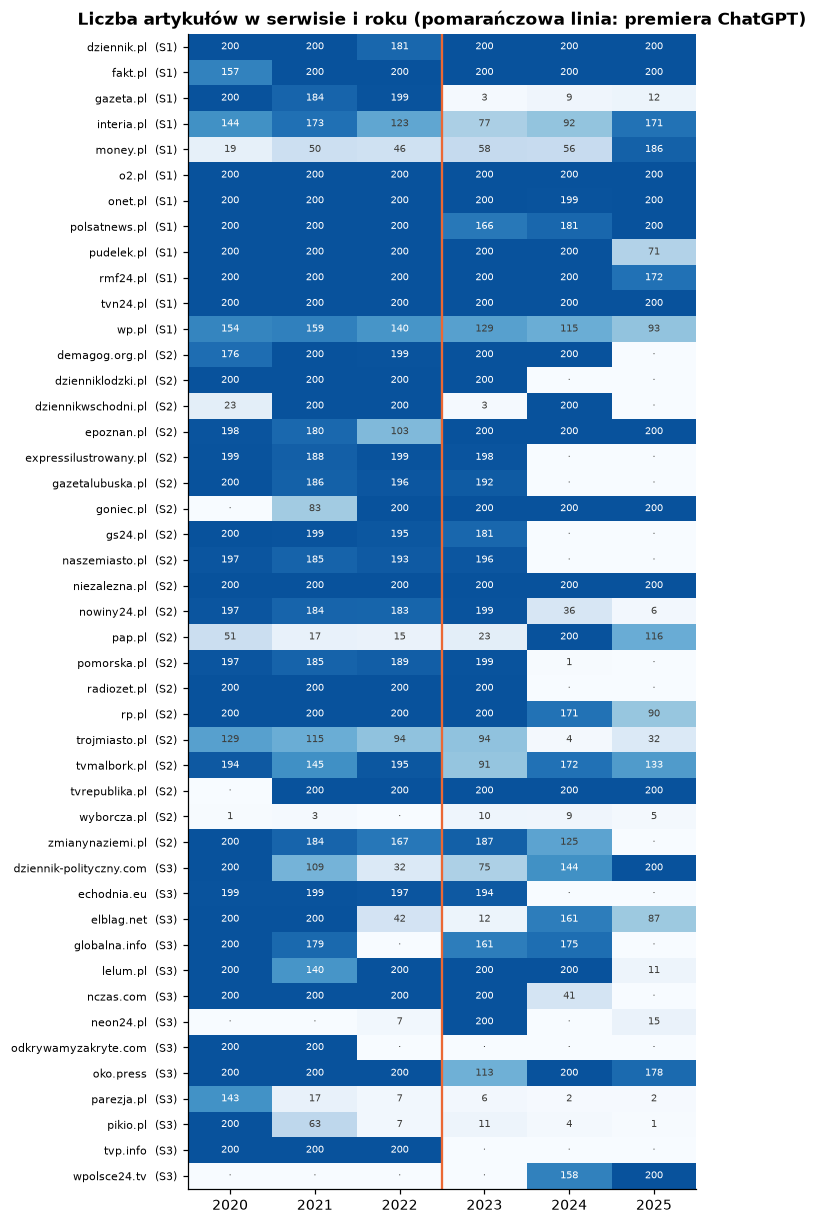

In [4]:
counts = pd.crosstab(articles["domain"], articles["pub_year"])
stratum_of = articles.groupby("domain")["stratum"].first()
order = sorted(counts.index, key=lambda d: (stratum_of[d], d))
counts = counts.loc[order]

fig, ax = plt.subplots(figsize=(6.5, 0.22 * len(counts) + 1.3))
ax.imshow(counts.to_numpy(), cmap="Blues", vmin=0, vmax=230, aspect="auto")
for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        value = counts.iat[i, j]
        ax.text(j, i, value if value else "·", ha="center", va="center", fontsize=6.5,
                color="white" if value > 130 else INK)
ax.set_xticks(range(counts.shape[1]), counts.columns)
ax.set_yticks(range(len(counts)), [f"{d}  ({stratum_of[d]})" for d in counts.index], fontsize=7)
ax.axvline(2.5, color=ORANGE, lw=1.5)
ax.grid(False)
ax.set_title("Liczba artykułów w serwisie i roku (pomarańczowa linia: premiera ChatGPT)")
fig.tight_layout()
plt.show()

In [5]:
n_period = (
    pd.crosstab(articles["domain"], articles["human"])
    .reindex(columns=[True, False], fill_value=0)
    .set_axis(["n 2020–22", "n 2023–25"], axis=1)
)
n_period["stratum"] = stratum_of
ELIGIBLE = n_period.index[(n_period["n 2020–22"] >= MIN_N) & (n_period["n 2023–25"] >= MIN_N)]
excluded = n_period.drop(index=ELIGIBLE).sort_values("stratum")

print(f"Serwisy z co najmniej {MIN_N} tekstami w obu okresach (wchodzą do analizy): {len(ELIGIBLE)}")
print(f"Serwisy wyłączone z porównania przed/po: {len(excluded)}")
display(excluded[["stratum", "n 2020–22", "n 2023–25"]])

Serwisy z co najmniej 50 tekstami w obu okresach (wchodzą do analizy): 37
Serwisy wyłączone z porównania przed/po: 8


,stratum,n 2020–22,n 2023–25
domain,,,
gazeta.pl,S1,583,24
wyborcza.pl,S2,4,24
neon24.pl,S3,7,215
odkrywamyzakryte.com,S3,400,0
parezja.pl,S3,167,10
pikio.pl,S3,270,16
tvp.info,S3,600,0
wpolsce24.tv,S3,0,358


**Co widać:**

- **Pokrycie jest nierówne.** Grupa serwisów regionalnych (np. `dzienniklodzki.pl`, `gs24.pl`, `pomorska.pl`, `echodnia.eu`) i `radiozet.pl` ma po 200 tekstów do 2023 r., a w latach 2024–2025 nie ma ich wcale. Niektóre serwisy są tylko przed 2023 r. (`tvp.info`) albo prawie tylko po 2022 r. (`neon24.pl`, `wpolsce24.tv`).
- **Konsekwencja:** porównanie „wszystkie artykuły z lat 2020–2022 kontra wszystkie z lat 2023–2025” mieszałoby zmianę w czasie ze zmianą składu serwisów. Dlatego **każdy serwis porównujemy z nim samym**, a wynik ogólny (sekcja 5) liczymy tak, żeby skład serwisów był w obu okresach taki sam.
- **Serwisy z mniej niż 50 tekstami w jednym z okresów** nie wchodzą do porównania. Odsetek liczony z kilkunastu tekstów zmienia się o kilkanaście punktów procentowych od jednego tekstu. Opisujemy je osobno na końcu sekcji 6.

## 2. Który detektor widzi AI w polskich newsach?

Kurs wymaga **sprawdzenia wiarygodności instrumentu na danych odniesienia**, czyli na tekstach, o których wiemy, kto je napisał. Mamy dwa takie zbiory.

### Zbiór gold (nasz, dopasowany do badanych danych)

Zbudowany w repozytorium (`src/news_detector/gold/`, wyniki w `docs/results/gold_eval/`):

- **G1: 100 ludzkich artykułów z 2020 r.** z 24 naszych serwisów. Losowanie po kolei z każdego serwisu (żaden nie dominuje), długość 200–1500 słów. Automatycznie odrzucone reklamy, artykuły sponsorowane, komunikaty prawne, listy i tabele. Po przeczytaniu odrzucono ręcznie jeszcze 14 tekstów (`config/g1_exclusions.csv`: advertoriale, biuletyny statystyczne, galerie).
- **G2: te same 100 artykułów napisane od nowa przez `gpt-4.1-mini`** (OpenAI, temperatura 0,7). Polecenie: napisać artykuł od nowa własnymi słowami, „jak dla redakcji, która przerabia cudzy materiał na własny”, z zachowaniem faktów, nazwisk, liczb i cytatów oraz długości 80–120% oryginału. Odpowiedzi, które kopiowały więcej niż 25% fraz (5-gramów) z oryginału, były oznaczane.

**Dlaczego ten zbiór jest cenny:** to polskie newsy z naszych serwisów, model komercyjny (takich najpewniej używają serwisy) i praktyka typowa dla farm treści, czyli przerabianie cudzych tekstów. Pary mają ten sam temat i podobną długość, więc różnica w wyniku detektora nie bierze się z tematu ani z długości.

**Ograniczenia:** jeden model generujący, jeden tryb (przeróbka, a nie pisanie od zera), 100 par. W repozytorium są tylko wyniki detektorów (teksty są prywatne), więc nie możemy ich policzyć ponownie, np. innym detektorem.

### Śmigiel (PolEval 2025)

1000 polskich tekstów: 500 ludzkich i 500 z modeli open-source (Bielik, PLLuM, Llama, Mistral, Gemma). Bardzo krótkie (mediana 49 słów) i nie są to newsy. Służy jako drugi, niezależny punkt odniesienia.

### Czy wyniki ze zbioru gold są porównywalne z naszymi?

Teksty G1 to artykuły z naszej próby, tylko dodatkowo oczyszczone ze śmieci (np. „Czytaj także”). Jeśli Pangram daje im w obu plikach podobne wyniki, możemy stosować do zbioru gold **te same progi** co do naszych danych.

In [6]:
gold = pd.read_csv(GOLD_SCORES)
gold["column"] = gold["detector"].map(GOLD_NAMES)

g1 = gold[(gold["detector"] == "pangram") & (gold["label"] == "human")]
same = g1.merge(data[["article_id", SCORE]].drop_duplicates("article_id"), left_on="pair_id", right_on="article_id")
diff = (same["raw"] - same[SCORE]).abs()
print(f"Artykuły G1 znalezione w naszych danych: {len(same)} ze {len(g1)}")
print(f"Pangram, średni wynik: gold {same['raw'].mean():.3f}, nasze dane {same[SCORE].mean():.3f}")
print(f"Mediana bezwzględnej różnicy wyniku: {diff.median():.4f} "
      f"(korelacja rang: {same[['raw', SCORE]].corr('spearman').iloc[0, 1]:.2f})")

Artykuły G1 znalezione w naszych danych: 100 ze 100
Pangram, średni wynik: gold 0.138, nasze dane 0.139
Mediana bezwzględnej różnicy wyniku: 0.0022 (korelacja rang: 0.87)


In [7]:
bielik = articles.merge(pd.read_csv(DETECT / "bielik-1.5b.csv"), on="text_key", how="inner")
smigiel = (
    pd.read_csv(SMIGIEL_SAMPLE)
    .assign(text_key=lambda f: f["text"].map(text_key))
    .drop(columns="text")
    .merge(pd.read_csv(DETECT / "smigiel-pangram.csv"), on="text_key")
    .merge(pd.read_csv(DETECT / "smigiel-bielik-1.5b.csv"), on="text_key")
)


def our_threshold(column: str, fpr: float) -> float:
    """Próg (w skali „wyżej = bardziej AI”) ustawiony na naszych tekstach z lat 2020–2022."""
    frame = data if column == SCORE else bielik
    calibration = frame["human"] & frame["split"].isin(["train", "dev"])
    return threshold_at_fpr(DIRECTIONS[column] * frame.loc[calibration, column], fpr)


rng = np.random.default_rng(SEED)
rows = []
for name, column in GOLD_NAMES.items():
    pairs = gold[gold["detector"] == name].pivot(index="pair_id", columns="label", values="score")
    boot = [auc(*pairs.sample(len(pairs), replace=True, random_state=rng)[["ai", "human"]].T.to_numpy())
            for _ in range(1000)]
    machine = DIRECTIONS[column] * smigiel[column]
    threshold = our_threshold(column, MAIN_FPR)
    rows.append({
        "detektor": DET_NAMES[column],
        "AUC gold [95% CI]": f"{auc(pairs['ai'], pairs['human']):.2f} "
                             f"[{np.percentile(boot, 2.5):.2f}; {np.percentile(boot, 97.5):.2f}]",
        "przeróbka wyżej niż oryginał": pct((pairs["ai"] > pairs["human"]).mean(), 0),
        "TPR gold przy naszym progu": pct((pairs["ai"] > threshold).mean(), 0),
        "AUC Śmigiel": f"{auc(machine[smigiel['label'] == 1], machine[smigiel['label'] == 0]):.2f}",
        "TPR Śmigiel przy naszym progu": pct((machine[smigiel["label"] == 1] > threshold).mean(), 0),
    })
validation = pd.DataFrame(rows).set_index("detektor")
display(validation)

,AUC gold [95% CI],przeróbka wyżej niż oryginał,TPR gold przy naszym progu,AUC Śmigiel,TPR Śmigiel przy naszym progu
detektor,,,,,
Pangram EditLens,0.88 [0.83; 0.92],89%,26%,0.80,45%
Binoculars (Bielik 1.5B),0.56 [0.50; 0.62],56%,2%,0.84,45%
"Fast-DetectGPT, model bazowy (Bielik 1.5B)",0.49 [0.43; 0.56],43%,4%,0.79,16%
"Fast-DetectGPT, model instrukcyjny (Bielik 1.5B)",0.56 [0.50; 0.63],54%,11%,0.80,32%
zwykła perplexity (Bielik 1.5B),0.77 [0.72; 0.81],92%,1%,0.71,13%


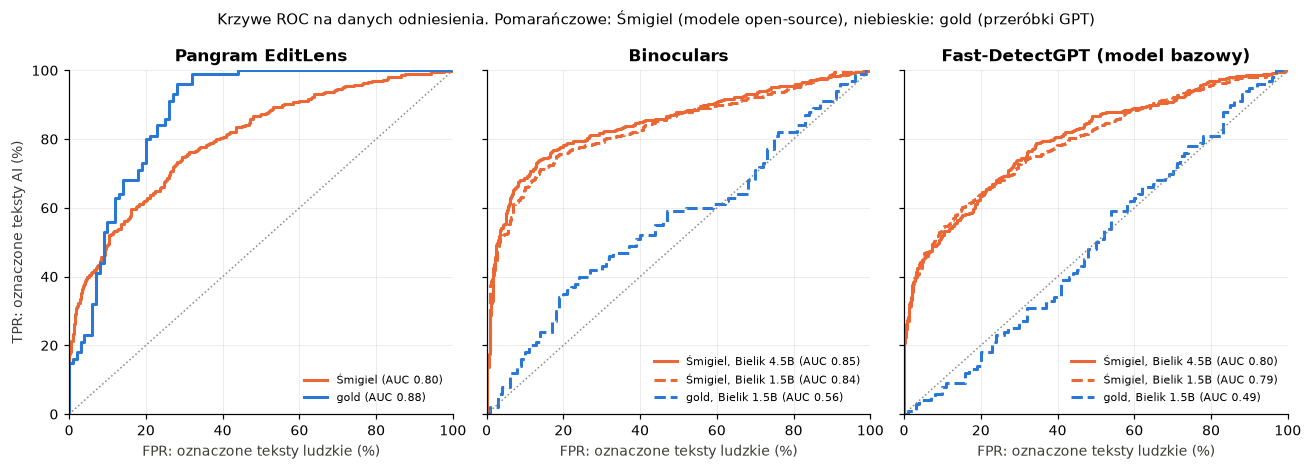

In [8]:
def roc_points(pos: np.ndarray, neg: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Krzywa ROC: (FPR, TPR) dla wszystkich możliwych progów."""
    is_ai = np.r_[np.ones(len(pos)), np.zeros(len(neg))][np.argsort(-np.concatenate([pos, neg]), kind="stable")]
    return np.r_[0, np.cumsum(1 - is_ai) / len(neg)], np.r_[0, np.cumsum(is_ai) / len(pos)]


smigiel45 = (
    pd.read_csv(SMIGIEL_SAMPLE)
    .assign(text_key=lambda f: f["text"].map(text_key))
    .drop(columns="text")
    .merge(pd.read_csv(DETECT / "smigiel-bielik-4.5b.csv"), on="text_key")
)
GOLD_OF = {column: name for name, column in GOLD_NAMES.items()}
ROC_PANELS = {SCORE: "Pangram EditLens", "binoculars": "Binoculars", "fastdetectgpt_observer": "Fast-DetectGPT (model bazowy)"}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), sharey=True)
for ax, (column, title) in zip(axes, ROC_PANELS.items()):
    is_pangram = column == SCORE
    curves = [("Śmigiel", smigiel, ORANGE, "-")] if is_pangram else [
        ("Śmigiel, Bielik 4.5B", smigiel45, ORANGE, "-"), ("Śmigiel, Bielik 1.5B", smigiel, ORANGE, "--")]
    sets = []
    for label, frame, color, style in curves:
        machine = DIRECTIONS[column] * frame[column]
        sets.append((label, machine[frame["label"] == 1].to_numpy(), machine[frame["label"] == 0].to_numpy(), color, style))
    pairs = gold[gold["detector"] == GOLD_OF[column]].pivot(index="pair_id", columns="label", values="score")
    sets.append(("gold" if is_pangram else "gold, Bielik 1.5B", pairs["ai"].to_numpy(), pairs["human"].to_numpy(),
                 BLUE, "-" if is_pangram else "--"))
    for label, pos, neg, color, style in sets:
        x, y = roc_points(pos, neg)
        ax.plot(100 * x, 100 * y, color=color, ls=style, lw=2, label=f"{label} (AUC {auc(pos, neg):.2f})")
    ax.plot([0, 100], [0, 100], color=GRAY, ls=":", lw=1)
    ax.set_title(title)
    ax.set_xlabel("FPR: oznaczone teksty ludzkie (%)")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.legend(loc="lower right", fontsize=7.5)
axes[0].set_ylabel("TPR: oznaczone teksty AI (%)")
fig.suptitle("Krzywe ROC na danych odniesienia. Pomarańczowe: Śmigiel (modele open-source), niebieskie: gold (przeróbki GPT)",
             fontsize=10)
fig.tight_layout()
plt.show()

**Jak czytać tabelę i wykres:**

- **Krzywa ROC** pokazuje wszystkie możliwe progi naraz: dla każdego progu, jaki odsetek tekstów AI (oś pionowa) wykrywamy za cenę jakiego odsetka fałszywych alarmów (oś pozioma). Detektor bez sygnału leży na przekątnej, idealny przechodzi przez lewy górny róg. AUC to pole pod tą krzywą.
- **AUC gold**: czy detektor w ogóle odróżnia przeróbki GPT od oryginałów, niezależnie od progu.
- **przeróbka wyżej niż oryginał**: w ilu parach (ten sam temat, ta sama długość) tekst z AI dostał wyższy wynik niż jego ludzki oryginał. 50% = detektor nie widzi różnicy.
- **TPR przy naszym progu**: jaka część tekstów AI zostałaby oznaczona przy progu, którego używamy na naszych danych (FPR 5%, sekcja 3). Tylko ta kolumna mówi, ile detektor wykryje **w naszej analizie**.

**Wnioski i decyzja:**

- **Pangram EditLens jest jedynym detektorem, który widzi przeróbki GPT w polskich newsach.** Ocenia przeróbkę wyżej niż oryginał w 89 parach na 100. Wyniki tych samych artykułów w zbiorze gold i w naszych danych są prawie identyczne, więc jego progi możemy przenosić między zbiorami.
- **Detektory oparte na Bieliku (Binoculars, Fast-DetectGPT) nie odróżniają przeróbek GPT od oryginałów** (AUC 0,49–0,56; przy naszym progu oznaczają 2–11% tekstów AI, czyli niewiele więcej niż 5% tekstów ludzkich). Na Śmigielu działają (AUC około 0,8), więc to nie jest błąd implementacji. Na wykresie widać to najlepiej: na Śmigielu krzywe Bielika wyraźnie odchodzą od przekątnej, a na gold leżą na niej. Widzą teksty pisane modelami podobnymi do Bielika, ale nie widzą tekstów GPT. Wynika z tego, że **brak wzrostu u tych detektorów (wcześniejsze analizy) nie jest dowodem braku AI**, tylko skutkiem ślepoty instrumentu na ten typ tekstów.
- *Zwykła perplexity* ma przyzwoite AUC na gold (0,77), ale przy naszym progu nie wykrywa prawie nic. To miara „gładkości” tekstu, mocno zależna od tematu, a nie detektor AI.
- **Bielik 4.5B nie ma wyników na gold** (kolega policzył tylko 1.5B). Na Śmigielu oba modele dają prawie te same krzywe, więc ślepota na przeróbki GPT najpewniej dotyczy też 4.5B, ale nie sprawdziliśmy tego bezpośrednio.
- Zastrzeżenie: wyniki Bielika w zbiorze gold liczono dla 1024 tokenów, a w naszych danych dla 512. Skala jest podobna, ale nie identyczna. Wniosek o AUC to zastrzeżenie nie dotyczy, bo AUC nie zależy od progu.

**Decyzja: główną analizę prowadzimy na Pangramie.** Pozostałe detektory opisujemy w raporcie jako wynik walidacji („instrument nie działa na tego typu tekstach”), a to, co pokazują na naszych danych, porównujemy z Pangramem w sekcji 8.

## 3. Próg, FPR i TPR: skąd biorą się liczby

### Jak ustawiamy próg

1. Bierzemy teksty z lat 2020–2022 ze zbiorów `train` i `dev` (90% tekstów z tych lat). Zakładamy, że są ludzkie.
2. Próg ustawiamy tak, żeby **dokładnie 5% z nich znalazło się powyżej** (95. percentyl wyniku). Tak *ustalamy* FPR = 5%.
3. Sprawdzamy, czy próg działa na tekstach, których nie użyliśmy: na zbiorze `test` z lat 2020–2022 (10% tekstów) i na ludzkich tekstach G1. Jeśli wyjdzie tam około 5%, próg przenosi się na nowe teksty.
4. Ten sam próg stosujemy do przeróbek G2. Odsetek oznaczonych wśród nich to **TPR**.

Robimy to dla kilku poziomów FPR, żeby pokazać, jak zmienia się czułość.

In [9]:
CALIBRATION = data["human"] & data["split"].isin(["train", "dev"])
HELDOUT = data["human"] & (data["split"] == "test")
gold_pg = gold[gold["detector"] == "pangram"]
gold_ai = gold_pg[gold_pg["label"] == "ai"].set_index("pair_id")["score"]
gold_human = gold_pg[gold_pg["label"] == "human"].set_index("pair_id")["score"]


def threshold(fpr: float) -> float:
    return threshold_at_fpr(data.loc[CALIBRATION, SCORE], fpr)


def gold_tpr(fpr: float) -> tuple[int, int]:
    """(liczba oznaczonych przeróbek G2, liczba przeróbek) przy progu dla danego FPR."""
    return int((gold_ai > threshold(fpr)).sum()), len(gold_ai)


rows = []
for fpr in (0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30):
    t = threshold(fpr)
    held = data.loc[HELDOUT, SCORE] > t
    k_ai, n_ai = gold_tpr(fpr)
    rows.append({
        "docelowy FPR": pct(fpr, 0),
        "próg (wynik Pangrama)": round(t, 3),
        "FPR na odłożonych tekstach 2020–22 [95% CI]": pct_ci(held.mean(), *wilson_interval(int(held.sum()), len(held))),
        "FPR na G1 (100 tekstów)": pct((gold_human > t).mean(), 0),
        "TPR na G2 [95% CI]": pct_ci(k_ai / n_ai, *wilson_interval(k_ai, n_ai)),
        "TPR − FPR": f"{k_ai / n_ai - fpr:.2f}",
    })
calibration = pd.DataFrame(rows).set_index("docelowy FPR")
display(calibration)

,próg (wynik Pangrama),FPR na odłożonych tekstach 2020–22 [95% CI],FPR na G1 (100 tekstów),TPR na G2 [95% CI],TPR − FPR
docelowy FPR,,,,,
1%,0.612,0.5% [0.3%; 0.9%],0%,10.0% [5.5%; 17.4%],0.09
2%,0.560,1.5% [1.1%; 2.2%],0%,15.0% [9.3%; 23.3%],0.13
5%,0.472,4.4% [3.6%; 5.3%],6%,26.0% [18.4%; 35.4%],0.21
10%,0.379,8.7% [7.6%; 10.0%],9%,45.0% [35.6%; 54.8%],0.35
15%,0.310,13.2% [11.8%; 14.7%],12%,61.0% [51.2%; 70.0%],0.46
20%,0.251,18.4% [16.8%; 20.2%],20%,78.0% [68.9%; 85.0%],0.58
30%,0.161,27.8% [25.9%; 29.8%],28%,96.0% [90.2%; 98.4%],0.66


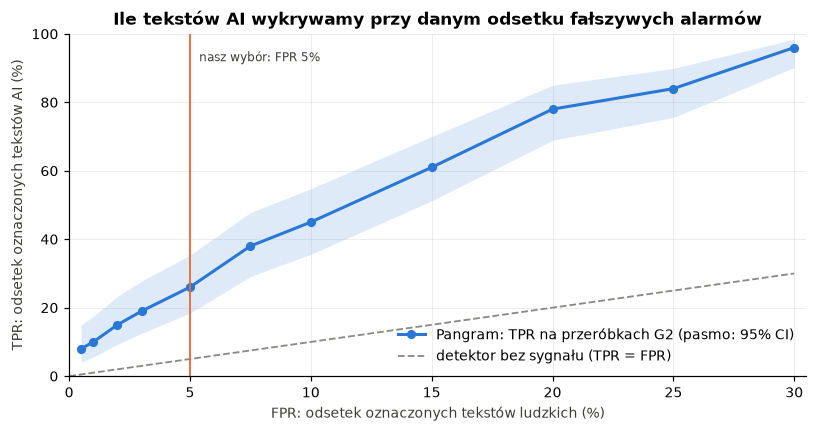

In [10]:
fpr_grid = np.array([0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30])
tpr = np.array([gold_tpr(f)[0] / gold_tpr(f)[1] for f in fpr_grid])
ci = np.array([wilson_interval(gold_tpr(f)[0], gold_tpr(f)[1]) for f in fpr_grid])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.fill_between(100 * fpr_grid, 100 * ci[:, 0], 100 * ci[:, 1], color=BLUE, alpha=0.15, lw=0)
ax.plot(100 * fpr_grid, 100 * tpr, color=BLUE, lw=2, marker="o", ms=5, label="Pangram: TPR na przeróbkach G2 (pasmo: 95% CI)")
ax.plot([0, 30], [0, 30], color=GRAY, ls="--", lw=1.2, label="detektor bez sygnału (TPR = FPR)")
ax.axvline(100 * MAIN_FPR, color=ORANGE, lw=1.2)
ax.annotate(f"nasz wybór: FPR {pct(MAIN_FPR, 0)}", (100 * MAIN_FPR, 92), xytext=(6, 0),
            textcoords="offset points", color=INK, fontsize=8)
ax.set_xlim(0, 30.5)
ax.set_ylim(0, 100)
ax.set_xlabel("FPR: odsetek oznaczonych tekstów ludzkich (%)")
ax.set_ylabel("TPR: odsetek oznaczonych tekstów AI (%)")
ax.set_title("Ile tekstów AI wykrywamy przy danym odsetku fałszywych alarmów")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

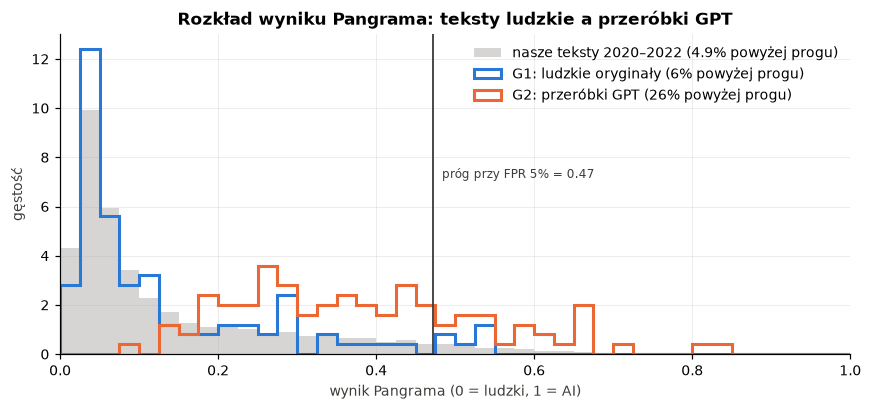

,klasa 0 (ludzki),klasa 1,klasa 2,klasa 3 (AI)
human,,,,
2020–2022,93.1%,2.8%,0.8%,3.3%
2023–2025,87.2%,5.5%,0.9%,6.4%


Najniższy wynik z klasą „AI”: 0.467 (nasz próg przy FPR 5%: 0.472).


In [11]:
cut = threshold(MAIN_FPR)
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(data.loc[data["human"], SCORE], bins=bins, density=True, histtype="stepfilled", color=GRAY, alpha=0.35,
        label=f"nasze teksty 2020–2022 ({pct((data.loc[data['human'], SCORE] > cut).mean())} powyżej progu)")
ax.hist(gold_human, bins=bins, density=True, histtype="step", color=BLUE, lw=2,
        label=f"G1: ludzkie oryginały ({pct((gold_human > cut).mean(), 0)} powyżej progu)")
ax.hist(gold_ai, bins=bins, density=True, histtype="step", color=ORANGE, lw=2,
        label=f"G2: przeróbki GPT ({pct((gold_ai > cut).mean(), 0)} powyżej progu)")
ax.axvline(cut, color=INK, lw=1.2)
ax.annotate(f"próg przy FPR {pct(MAIN_FPR, 0)} = {cut:.2f}", (cut, ax.get_ylim()[1] * 0.55), xytext=(6, 0),
            textcoords="offset points", fontsize=8, color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("wynik Pangrama (0 = ludzki, 1 = AI)")
ax.set_ylabel("gęstość")
ax.set_title("Rozkład wyniku Pangrama: teksty ludzkie a przeróbki GPT")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

classes = pd.crosstab(data["human"].map({True: "2020–2022", False: "2023–2025"}), data["pangram_bucket"], normalize="index")
classes.columns = [f"klasa {c}" + (" (ludzki)" if c == 0 else " (AI)" if c == classes.columns.max() else "") for c in classes.columns]
display(classes.map(pct))
print(f"Najniższy wynik z klasą „AI”: {data.loc[data['pangram_bucket'] == data['pangram_bucket'].max(), SCORE].min():.3f} "
      f"(nasz próg przy FPR {pct(MAIN_FPR, 0)}: {cut:.3f}).")

**Co pokazują tabela i wykresy:**

- **Progi przenoszą się na nowe teksty.** Na odłożonych tekstach z lat 2020–2022 odsetek oznaczonych jest blisko docelowego FPR albo nieco poniżej (4,4% przy docelowych 5%), a na 100 tekstach G1 mieści się w granicach losowości (6%).
- **Czułość przy niskim FPR jest niska.** Przy FPR 5% Pangram oznacza 26 ze 100 przeróbek GPT, a przy FPR 1% tylko 10. AUC jest wysokie (0,88), bo przeróbki mają *zwykle wyższy* wynik niż oryginał, ale *rzadko przekraczają* próg ustawiony na najbardziej „AI-podobnych” 5% tekstów ludzkich. Widać to na histogramie: rozkład przeróbek (pomarańczowy) jest wyraźnie przesunięty w prawo względem oryginałów, ale jego większość leży jeszcze przed progiem.
- **Nasz próg prawie pokrywa się z granicą klasy „AI” samego Pangrama** (0,47). Gdybyśmy liczyli po prostu teksty z klasą „AI”, dostalibyśmy praktycznie to samo oznaczenie. Różnica jest w tym, co robimy dalej: zamiast traktować 3,3% tekstów z lat 2020–2022 z klasą „AI” jako teksty AI, traktujemy je jako fałszywe alarmy i odejmujemy (sekcja 0).

**Dlaczego główny FPR to 5%:**

1. **Przy 1% detektor prawie nic nie widzi** (TPR 10%). Nadwyżka w serwisie byłaby ułamkiem punktu procentowego, a każdy błąd mnożyłby się przez 1 / (TPR − b) ≈ 11.
2. **Przy wyższym FPR (10–20%) czułość rośnie, ale próg schodzi w środek rozkładu tekstów ludzkich.** Tam wynik Pangrama silniej zależy od gatunku i długości tekstu, więc rośnie **dryf**: zmiany w czasie niezwiązane z AI (sekcja 4 pokazuje, że margines dryfu rośnie razem z FPR).
3. **5% to poziom ustalony przed analizą** (używaliśmy go od początku projektu), więc wybór nie jest dopasowany do wyniku. Inne progi pokazujemy w sekcji 7 jako analizę odporności.

### Co TPR = 26% oznacza dla naszych szacunków

Wiemy dokładnie, jaki jest TPR dla **przeróbek GPT-4.1-mini**. Nie wiemy, jaki jest dla tekstów, które serwisy faktycznie publikują: inny model, pisanie od zera, tłumaczenie, poprawki człowieka. Dlatego podajemy dla każdego serwisu **dwa szacunki udziału AI**:

| Szacunek | Założenie o TPR | Kiedy jest prawdziwy | Charakter |
|---|---|---|---|
| **π_min** | TPR = 100% | zawsze, jeśli poziom bazowy się nie zmienił (detektor nie może wykrywać więcej niż 100% tekstów AI) | **dolna granica**: prawdziwy udział nie może być mniejszy |
| **π_gold** | TPR z przeróbek G2 (26% przy FPR 5%) | jeśli teksty AI w serwisie są tak trudne do wykrycia jak przeróbki | szacunek realistyczny dla przeróbek; jeśli serwis generuje teksty od zera, które są łatwiejsze do wykrycia, **przeszacowuje** udział |

Wynik π_gold większy niż 100% (obcinamy go do 100%) znaczy, że w serwisie oznaczonych jest więcej tekstów, niż dałyby przeróbki, nawet gdyby wszystkie teksty pochodziły z AI. Teksty AI w tym serwisie są więc **łatwiejsze** do wykrycia niż nasze przeróbki.

## 4. Czy detektor jest stabilny w czasie bez AI?

Wzór na udział AI zakłada, że **bez AI odsetek oznaczonych by się nie zmienił**. Gdyby detektor reagował na zmianę tematów, stylu lub szablonu strony, nadwyżka pojawiłaby się bez udziału AI. Sprawdzamy to na dwa sposoby.

### 4.1. Odsetek oznaczonych w kolejnych latach

Linia niebieska: wszystkie serwisy. Linia pomarańczowa: tylko serwisy, które mają co najmniej 30 tekstów w **każdym** roku (stały skład, więc zmiana składu nie wpływa na wynik). Przerywana: docelowy FPR.

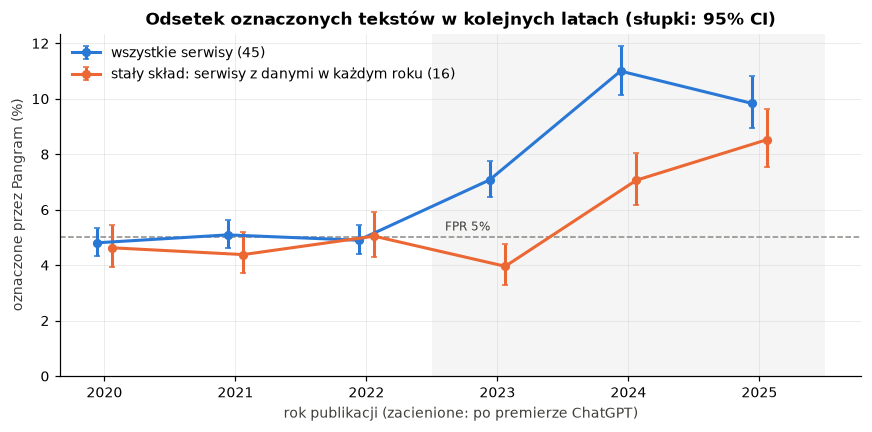

rok,2020,2021,2022,2023,2024,2025
n,3047,2966,2774,2651,2874,2708
odsetek,4.6%,4.4%,5.0%,4.0%,7.1%,8.5%


Serwisy o stałym składzie: dziennik-polityczny.com, dziennik.pl, epoznan.pl, fakt.pl, interia.pl, niezalezna.pl, o2.pl, oko.press, onet.pl, polsatnews.pl, pudelek.pl, rmf24.pl, rp.pl, tvmalbork.pl, tvn24.pl, wp.pl


In [12]:
flags_main = data[SCORE] > threshold(MAIN_FPR)
per_year_n = pd.crosstab(data["domain"], data["pub_year"])
balanced = per_year_n.index[(per_year_n >= 30).all(axis=1)]


def rate_by_year(mask: pd.Series) -> pd.DataFrame:
    rows = []
    for year, idx in data[mask].groupby("pub_year").groups.items():
        k, n = int(flags_main[idx].sum()), len(idx)
        rows.append({"rok": year, "n": n, "odsetek": k / n, **dict(zip(["low", "high"], wilson_interval(k, n)))})
    return pd.DataFrame(rows).set_index("rok")


series = {
    f"wszystkie serwisy ({data['domain'].nunique()})": (rate_by_year(data["domain"].notna()), BLUE, -0.06),
    f"stały skład: serwisy z danymi w każdym roku ({len(balanced)})": (rate_by_year(data["domain"].isin(balanced)), ORANGE, 0.06),
}
fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(100 * MAIN_FPR, color=GRAY, ls="--", lw=1)
ax.axvspan(2022.5, 2025.5, color=GRAY, alpha=0.08, lw=0)
for label, (table, color, shift) in series.items():
    ax.errorbar(table.index + shift, 100 * table["odsetek"],
                yerr=[100 * (table["odsetek"] - table["low"]), 100 * (table["high"] - table["odsetek"])],
                color=color, lw=2, marker="o", ms=5, capsize=2, label=label)
ax.text(2022.6, 100 * MAIN_FPR + 0.25, f"FPR {pct(MAIN_FPR, 0)}", color=INK, fontsize=8)
ax.set_xticks(range(2020, 2026))
ax.set_ylim(0, None)
ax.set_xlabel("rok publikacji (zacienione: po premierze ChatGPT)")
ax.set_ylabel("oznaczone przez Pangram (%)")
ax.set_title("Odsetek oznaczonych tekstów w kolejnych latach (słupki: 95% CI)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
display(series[list(series)[1]][0].assign(odsetek=lambda t: t["odsetek"].map(pct))[["n", "odsetek"]].T)
print("Serwisy o stałym składzie:", ", ".join(balanced))

### 4.2. Placebo: jak duże zmiany zdarzają się w serwisie bez AI?

Dla każdego serwisu porównujemy jeden rok z lat 2020–2022 z dwoma pozostałymi (np. 2022 kontra 2020–2021). AI nie było w żadnym z nich, więc każda różnica to **losowość albo dryf**.
Rozkład tych różnic pokazuje, jak duże „nadwyżki” powstają bez AI. Jego 95. percentyl nazywamy **marginesem dryfu δ**.

Nadwyżkę po 2022 r. uznajemy za realną tylko wtedy, gdy jest **większa niż δ**. To ostrożne kryterium, bo porównanie jednego roku z dwoma ma więcej losowego szumu niż porównanie trzech lat z trzema, więc δ jest raczej zawyżone.

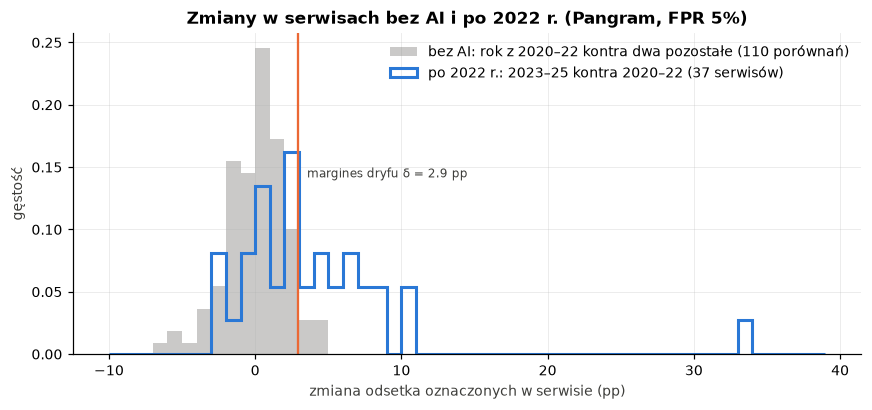

Bez AI: mediana +0.2 pp, 95. percentyl +2.9 pp. Po 2022 r.: mediana +2.5 pp; nadwyżkę większą niż δ ma 17 z 37 serwisów.


In [13]:
def placebo_changes(flags: pd.Series) -> np.ndarray:
    """Różnica odsetka oznaczonych: jeden rok z lat 2020–22 minus dwa pozostałe, dla każdej domeny."""
    changes = []
    for _, group in data[data["human"]].groupby("domain"):
        f = flags[group.index]
        for year in sorted(GOLD_YEARS):
            this = (group["pub_year"] == year).to_numpy()
            if this.sum() >= MIN_N and (~this).sum() >= MIN_N:
                changes.append(f[this].mean() - f[~this].mean())
    return np.array(changes)


def domain_rates(flags: pd.Series) -> pd.DataFrame:
    """Liczba tekstów i oznaczonych w każdej domenie przed i po 2022 r. (tylko domeny z ELIGIBLE)."""
    sub = data[data["domain"].isin(ELIGIBLE)]
    table = (
        pd.DataFrame({"domain": sub["domain"], "human": sub["human"], "flag": flags[sub.index]})
        .groupby(["domain", "human"])["flag"].agg(["sum", "size"]).unstack("human")
    )
    out = pd.DataFrame({
        "stratum": stratum_of[table.index],
        "n0": table[("size", True)], "k0": table[("sum", True)],
        "n1": table[("size", False)], "k1": table[("sum", False)],
    })
    out["b"] = out["k0"] / out["n0"]
    out["r"] = out["k1"] / out["n1"]
    out["nadwyżka"] = out["r"] - out["b"]
    return out


placebo = placebo_changes(flags_main)
DELTA = float(np.quantile(placebo, PLACEBO_Q))
real = domain_rates(flags_main)["nadwyżka"]

bins = np.arange(-0.10, 0.40, 0.01)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(100 * placebo, bins=100 * bins, density=True, histtype="stepfilled", color=GRAY, alpha=0.45,
        label=f"bez AI: rok z 2020–22 kontra dwa pozostałe ({len(placebo)} porównań)")
ax.hist(100 * real, bins=100 * bins, density=True, histtype="step", color=BLUE, lw=2,
        label=f"po 2022 r.: 2023–25 kontra 2020–22 ({len(real)} serwisów)")
ax.axvline(100 * DELTA, color=ORANGE, lw=1.5)
ax.annotate(f"margines dryfu δ = {100 * DELTA:.1f} pp", (100 * DELTA, ax.get_ylim()[1] * 0.55),
            xytext=(6, 0), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("zmiana odsetka oznaczonych w serwisie (pp)")
ax.set_ylabel("gęstość")
ax.set_title("Zmiany w serwisach bez AI i po 2022 r. (Pangram, FPR 5%)")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
print(f"Bez AI: mediana {100 * np.median(placebo):+.1f} pp, 95. percentyl {100 * DELTA:+.1f} pp. "
      f"Po 2022 r.: mediana {100 * real.median():+.1f} pp; nadwyżkę większą niż δ ma "
      f"{int((real > DELTA).sum())} z {len(real)} serwisów.")

**Wnioski z kontroli:**

- **W latach 2020–2022 odsetek oznaczonych jest płaski** (około 5%), także w stałym składzie serwisów.
- **W stałym składzie wzrost zaczyna się w 2024 r.** (4,0% w 2023, 7,1% w 2024, 8,5% w 2025). Wzrost w 2023 r. we wszystkich serwisach (7,1%) pochodzi więc z serwisów spoza stałego składu (np. `zmianynaziemi.pl`, `neon24.pl`). Wzrost w latach 2024–2025 jest widoczny w obu wariantach, więc nie wynika ze zmiany składu.
- **Bez AI zmiany w serwisie są małe i symetryczne wokół zera.** Po 2022 r. cały rozkład przesuwa się w prawo, a duża część serwisów ma nadwyżkę większą niż jakakolwiek typowa zmiana bez AI.
- Kontrola nie wyklucza dryfu, który zaczął się dokładnie w 2023 r. (np. nowy szablon strony albo nowa moda redakcyjna). Wyklucza jednak, że detektor „pływa” sam z siebie z roku na rok.

## 5. Wynik ogólny: ile tekstów AI przybyło po 2022 r.?

Liczymy jeden wynik dla wszystkich serwisów z analizy, z poprawką na skład: **poziom bazowy dopasowujemy do składu serwisów po 2022 r.** Każdy serwis wchodzi do poziomu bazowego z wagą równą liczbie jego tekstów z lat 2023–2025. Odpowiada to pytaniu: „ile tekstów byłoby oznaczonych w latach 2023–2025, gdyby każdy serwis zachowywał się jak w latach 2020–2022?”.

Niepewność liczymy, losując serwisy ze zwracaniem (wynik nie może zależeć od kilku serwisów) oraz losując TPR zgodny z wynikiem na G2.

In [14]:
def overall(flags: pd.Series, tpr_k: int, tpr_n: int, years=None, seed: int = SEED) -> dict:
    rates = domain_rates(flags)
    if years is not None:
        sub = data[data["domain"].isin(ELIGIBLE) & data["pub_year"].isin(years)]
        post = pd.DataFrame({"domain": sub["domain"], "flag": flags[sub.index]}).groupby("domain")["flag"]
        rates["n1"] = post.size().reindex(rates.index, fill_value=0)
        rates["k1"] = post.sum().reindex(rates.index, fill_value=0)
    n1, k1, b = rates["n1"].to_numpy(), rates["k1"].to_numpy(), rates["b"].to_numpy()

    def estimate(idx, tpr_value):
        base = (n1[idx] * b[idx]).sum(axis=-1) / n1[idx].sum(axis=-1)
        rate = k1[idx].sum(axis=-1) / n1[idx].sum(axis=-1)
        return base, rate, share(rate, base, 1.0), share(rate, base, tpr_value)

    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(rates), (N_BOOT, len(rates)))
    tpr_draws = draw_rate(tpr_k, tpr_n, rng)
    base, rate, p_min, p_gold = estimate(np.arange(len(rates)), tpr_k / tpr_n)
    _, _, b_min, b_gold = estimate(idx, tpr_draws)
    q = lambda x: np.percentile(x, [2.5, 97.5])
    return {
        "tekstów 2023–25": int(n1.sum()),
        "oznaczone: poziom bazowy (skład 2023–25)": pct(base),
        "oznaczone: 2023–25": pct(rate),
        "nadwyżka (pp)": f"{100 * (rate - base):+.1f}",
        "π_min: udział AI, dolna granica [95% CI]": pct_ci(p_min, *q(b_min)),
        "π_gold: udział AI przy TPR z G2 [95% CI]": pct_ci(p_gold, *q(b_gold)),
    }


k_tpr, n_tpr = gold_tpr(MAIN_FPR)
overall_table = pd.DataFrame({
    label: overall(flags_main, k_tpr, n_tpr, years)
    for label, years in (("2023", [2023]), ("2024", [2024]), ("2025", [2025]), ("2023–2025", None))
}).T
display(overall_table)

,tekstów 2023–25,oznaczone: poziom bazowy (skład 2023–25),oznaczone: 2023–25,nadwyżka (pp),"π_min: udział AI, dolna granica [95% CI]",π_gold: udział AI przy TPR z G2 [95% CI]
2023,5948,4.7%,5.7%,+0.9,1.0% [0.0%; 2.1%],4.3% [0.0%; 10.7%]
2024,4673,4.9%,11.0%,+6.1,6.4% [3.2%; 11.6%],29.0% [13.1%; 59.2%]
2025,3546,4.5%,10.2%,+5.8,6.1% [3.0%; 10.0%],26.8% [12.3%; 51.9%]
2023–2025,14167,4.7%,8.6%,+3.8,4.0% [2.4%; 6.1%],18.1% [9.7%; 32.2%]


**Jak to czytać:**

- W serwisach z analizy Pangram oznacza w latach 2023–2025 **8,6%** tekstów, a gdyby te same serwisy zachowywały się jak w latach 2020–2022, oznaczałby **4,7%**. Nadwyżka wynosi **3,8 pp**.
- **Udział tekstów AI w latach 2023–2025 wynosi od co najmniej 4% (π_min, 95% CI 2–6%) do około 18% (π_gold, 95% CI 10–32%).** Prawdziwa wartość leży bliżej dolnej granicy, jeśli teksty AI w serwisach są łatwiejsze do wykrycia niż nasze przeróbki, a bliżej górnej, jeśli są tak samo trudne.
- **W 2023 r. nadwyżka jest mała** (π_gold 4%, przedział obejmuje zero), a **w latach 2024–2025 wyraźna** (π_gold 27–29%, π_min około 6%). Zjawisko narasta z opóźnieniem względem premiery ChatGPT, co pasuje do stopniowego wdrażania narzędzi w redakcjach.
- Przedziały są szerokie, bo czułość znamy tylko ze 100 przeróbek. To główne źródło niepewności w całym badaniu.

## 6. Wynik dla domen: które serwisy publikują masowo?

### Reguła (ustalona przed obejrzeniem wyników dla domen)

Dla każdego serwisu liczymy π_min i π_gold z 95% przedziałami ufności. Niepewność obejmuje losowość odsetków przed i po 2022 r. oraz niepewność TPR. Serwis zaliczamy do jednej z czterech grup:

| Grupa | Warunek | Znaczenie |
|---|---|---|
| **masowo: mocne dowody** | nadwyżka > δ **i** dolna granica CI dla π_min ≥ 20% | nawet przy idealnym detektorze co najmniej co piąty tekst jest z AI |
| **masowo: prawdopodobnie** | nadwyżka > δ **i** dolna granica CI dla π_gold ≥ 20% (ale nie powyższe) | co najmniej 20%, jeśli teksty AI w serwisie są tak trudne do wykrycia jak przeróbki GPT |
| **nadwyżka poniżej progu** | nadwyżka > δ, ale żaden z powyższych warunków | sygnał AI jest, ale nie da się wykazać, że jest masowy |
| **brak nadwyżki ponad dryf** | nadwyżka ≤ δ | nic nie odróżnia tego serwisu od zmian, które zdarzają się bez AI |

In [15]:
CATEGORIES = ["masowo: mocne dowody", "masowo: prawdopodobnie", "nadwyżka poniżej progu", "brak nadwyżki ponad dryf"]


def domain_shares(flags: pd.Series, tpr_k: int, tpr_n: int, delta: float,
                  mass: float = MASS_SHARE, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    table = domain_rates(flags)
    tpr_draws = draw_rate(tpr_k, tpr_n, rng)
    rows = []
    for domain, row in table.iterrows():
        b_draws = draw_rate(row["k0"], row["n0"], rng)
        r_draws = draw_rate(row["k1"], row["n1"], rng)
        p_min, p_gold = share(r_draws, b_draws, 1.0), share(r_draws, b_draws, tpr_draws)
        rows.append({
            "π_min": float(share(row["r"], row["b"], 1.0)),
            "π_min low": np.percentile(p_min, 2.5), "π_min high": np.percentile(p_min, 97.5),
            "π_gold": float(share(row["r"], row["b"], tpr_k / tpr_n)),
            "π_gold low": np.percentile(p_gold, 2.5), "π_gold high": np.percentile(p_gold, 97.5),
        })
    table = table.join(pd.DataFrame(rows, index=table.index))
    table["grupa"] = np.select(
        [table["nadwyżka"] <= delta, table["π_min low"] >= mass, table["π_gold low"] >= mass],
        [CATEGORIES[3], CATEGORIES[0], CATEGORIES[1]],
        default=CATEGORIES[2],
    )
    return table.sort_values(["π_gold", "π_min"], ascending=False)


domains = domain_shares(flags_main, k_tpr, n_tpr, DELTA)


def show_domains(table: pd.DataFrame) -> None:
    view = pd.DataFrame({
        "stratum": table["stratum"],
        "n 2020–22": table["n0"], "oznaczone 2020–22": table["b"].map(pct),
        "n 2023–25": table["n1"], "oznaczone 2023–25": table["r"].map(pct),
        "nadwyżka (pp)": (100 * table["nadwyżka"]).map("{:+.1f}".format),
        "π_min [95% CI]": [pct_ci(*v) for v in table[["π_min", "π_min low", "π_min high"]].to_numpy()],
        "π_gold [95% CI]": [pct_ci(*v) for v in table[["π_gold", "π_gold low", "π_gold high"]].to_numpy()],
        "grupa": table["grupa"],
    })
    display(view)


show_domains(domains)

,stratum,n 2020–22,oznaczone 2020–22,n 2023–25,oznaczone 2023–25,nadwyżka (pp),π_min [95% CI],π_gold [95% CI],grupa
domain,,,,,,,,,
zmianynaziemi.pl,S2,551,3.1%,312,36.5%,+33.5,34.5% [28.9%; 40.3%],100.0% [99.4%; 100.0%],masowo: mocne dowody
pap.pl,S2,83,6.0%,339,16.2%,+10.2,10.9% [2.7%; 16.5%],51.1% [15.6%; 92.8%],nadwyżka poniżej progu
goniec.pl,S2,283,5.3%,600,15.7%,+10.4,10.9% [6.8%; 14.7%],50.1% [28.9%; 84.9%],masowo: prawdopodobnie
globalna.info,S3,379,9.8%,336,17.3%,+7.5,8.3% [2.7%; 13.7%],46.2% [15.1%; 100.0%],nadwyżka poniżej progu
elblag.net,S3,442,6.6%,260,15.0%,+8.4,9.0% [4.0%; 14.2%],43.4% [18.7%; 84.2%],nadwyżka poniżej progu
nczas.com,S3,600,3.5%,241,12.4%,+8.9,9.3% [5.0%; 14.1%],39.8% [20.0%; 72.0%],masowo: prawdopodobnie
demagog.org.pl,S2,575,10.8%,400,16.8%,+6.0,6.7% [1.8%; 11.6%],39.2% [9.9%; 91.8%],nadwyżka poniżej progu
tvmalbork.pl,S2,534,3.6%,396,10.4%,+6.8,7.0% [3.7%; 10.6%],30.3% [15.5%; 54.7%],nadwyżka poniżej progu
lelum.pl,S3,540,2.0%,411,9.2%,+7.2,7.4% [4.4%; 10.6%],30.1% [16.7%; 51.1%],nadwyżka poniżej progu


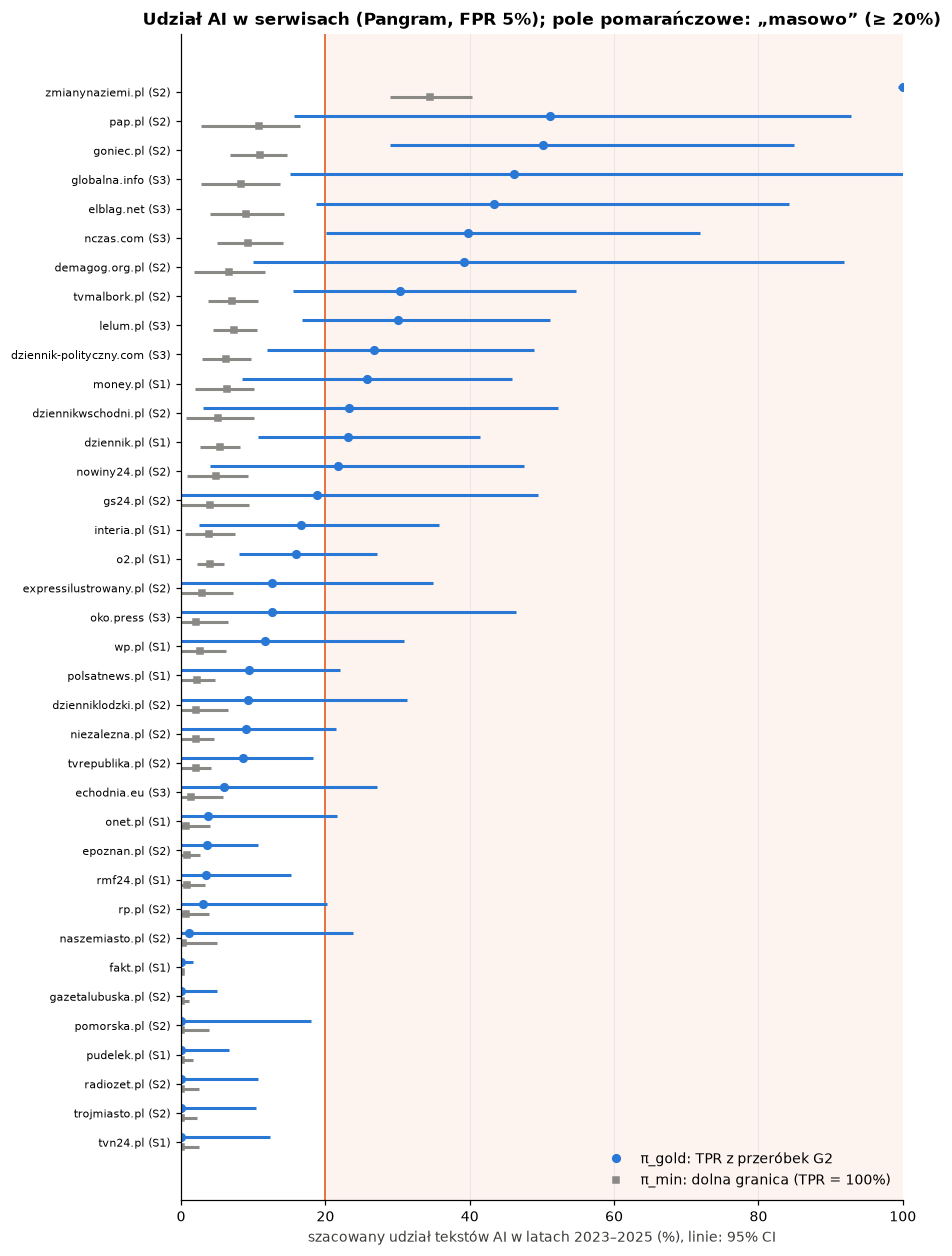

In [16]:
shown = domains.iloc[::-1]
y = np.arange(len(shown))
fig, ax = plt.subplots(figsize=(8.5, 0.27 * len(shown) + 1.5))
ax.axvspan(100 * MASS_SHARE, 100, color=ORANGE, alpha=0.07, lw=0)
ax.axvline(100 * MASS_SHARE, color=ORANGE, lw=1.2)
ax.hlines(y + 0.17, 100 * shown["π_gold low"], 100 * shown["π_gold high"], color=BLUE, lw=2)
ax.plot(100 * shown["π_gold"], y + 0.17, "o", color=BLUE, ms=5, label="π_gold: TPR z przeróbek G2")
ax.hlines(y - 0.17, 100 * shown["π_min low"], 100 * shown["π_min high"], color=GRAY, lw=2)
ax.plot(100 * shown["π_min"], y - 0.17, "s", color=GRAY, ms=4.5, label="π_min: dolna granica (TPR = 100%)")
ax.set_yticks(y, [f"{d} ({s})" for d, s in zip(shown.index, shown["stratum"])], fontsize=7.5)
ax.set_xlim(0, 100)
ax.set_xlabel("szacowany udział tekstów AI w latach 2023–2025 (%), linie: 95% CI")
ax.set_title(f"Udział AI w serwisach (Pangram, FPR {pct(MAIN_FPR, 0)}); pole pomarańczowe: „masowo” (≥ {pct(MASS_SHARE, 0)})")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

In [17]:
summary = (
    pd.crosstab(domains["grupa"], domains["stratum"], margins=True, margins_name="razem")
    .reindex(index=CATEGORIES + ["razem"], fill_value=0)
)
display(summary)
for category in CATEGORIES[:2]:
    names = domains.index[domains["grupa"] == category]
    print(f"{category}: {', '.join(names) if len(names) else 'brak'}")

stratum,S1,S2,S3,razem
grupa,,,,
masowo: mocne dowody,0,1,0,1
masowo: prawdopodobnie,0,1,1,2
nadwyżka poniżej progu,4,6,4,14
brak nadwyżki ponad dryf,7,11,2,20
razem,11,19,7,37


masowo: mocne dowody: zmianynaziemi.pl
masowo: prawdopodobnie: goniec.pl, nczas.com


### Kiedy to się zaczęło?

Odsetek oznaczonych tekstów rok po roku w serwisach „masowych” i w najmocniejszym kandydacie spoza porównania (najwyższy odsetek oznaczonych wśród wyłączonych serwisów z co najmniej 100 tekstami po 2022 r.). Pod rokiem: liczba tekstów.

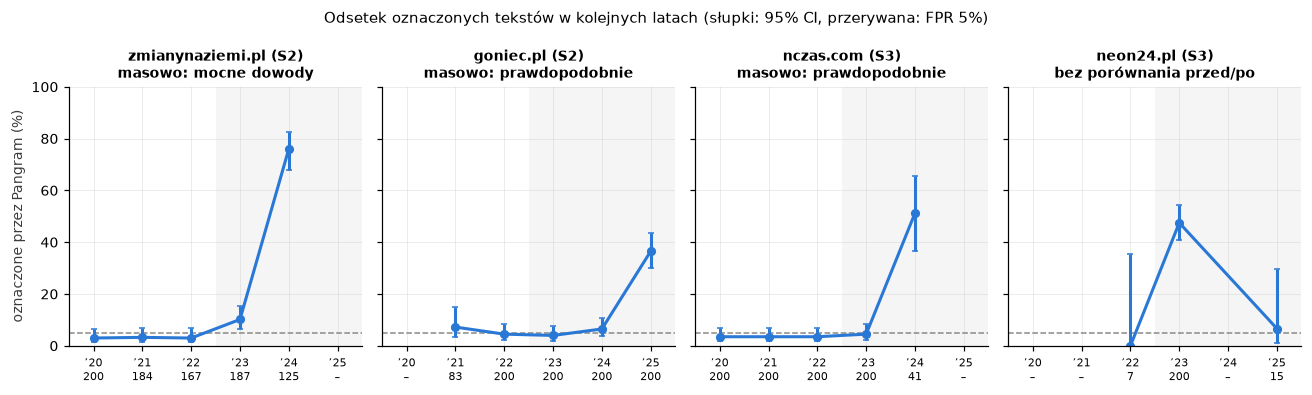

In [18]:
highlight = list(domains.index[domains["grupa"].isin(CATEGORIES[:2])])
post_rate = {
    d: flags_main[(data["domain"] == d) & ~data["human"]].mean()
    for d in excluded.index if excluded.loc[d, "n 2023–25"] >= 100
}
highlight.append(max(post_rate, key=post_rate.get))

fig, axes = plt.subplots(1, len(highlight), figsize=(3 * len(highlight), 3.6), sharey=True)
for ax, domain in zip(axes, highlight):
    mask = data["domain"] == domain
    t = flags_main[mask].groupby(data.loc[mask, "pub_year"]).agg(["sum", "size"])
    rate = t["sum"] / t["size"]
    ci = np.array([wilson_interval(int(k), int(n)) for k, n in t.to_numpy()])
    ax.axvspan(2022.5, 2025.5, color=GRAY, alpha=0.08, lw=0)
    ax.axhline(100 * MAIN_FPR, color=GRAY, ls="--", lw=1)
    ax.errorbar(t.index, 100 * rate, yerr=[100 * (rate - ci[:, 0]), 100 * (ci[:, 1] - rate)],
                color=BLUE, lw=2, marker="o", ms=5, capsize=2)
    status = domains.loc[domain, "grupa"] if domain in domains.index else "bez porównania przed/po"
    ax.set_title(f"{domain} ({stratum_of[domain]})\n{status}", fontsize=9)
    ax.set_xlim(2019.5, 2025.5)
    n_year = t["size"].reindex(range(2020, 2026), fill_value=0)
    ax.set_xticks(range(2020, 2026), [f"’{y % 100}\n{n if n else '–'}" for y, n in n_year.items()], fontsize=7.5)
    ax.set_ylim(0, 100)
axes[0].set_ylabel("oznaczone przez Pangram (%)")
fig.suptitle(f"Odsetek oznaczonych tekstów w kolejnych latach (słupki: 95% CI, przerywana: FPR {pct(MAIN_FPR, 0)})", fontsize=10)
fig.tight_layout()
plt.show()

**Jak to czytać:**

- **Wzrost jest skokowy, a nie stopniowy.** W każdym z tych serwisów odsetek oznaczonych przez kilka lat leży przy FPR (3–7%), a potem w ciągu jednego roku skacze do 36–76%. Tak wygląda przejście na automatyczną produkcję treści, a nie powolna zmiana stylu redakcji.
- **Skoki przypadają na różne lata:** `neon24.pl` w 2023 r. (48%), `zmianynaziemi.pl` i `nczas.com` w 2024 r. (76% i 51%), `goniec.pl` dopiero w 2025 r. (37%). Nie ma więc jednego wspólnego zdarzenia, które tłumaczyłoby wszystkie skoki naraz. Skoku w pojedynczym serwisie nie można jednak odróżnić od zmiany szablonu strony albo działu, z którego crawl pobrał teksty. Wykluczyłoby to dopiero ręczne przejrzenie tekstów.
- **Nasza reguła uśrednia lata 2023–2025, więc jest ostrożna dla serwisów, które przeszły na AI później.** W `zmianynaziemi.pl` w samym 2024 r. dolna granica udziału AI wynosi około 75%, a w `goniec.pl` w samym 2025 r. około 33%.
- **Dlaczego `nczas.com` jest kruchy:** cały jego sygnał pochodzi ze 41 tekstów z 2024 r. (51% oznaczonych) i nie ma danych z 2025 r. Skok jest duży, ale opiera się na małej próbie.

### Serwisy bez porównania przed/po

Te serwisy nie spełniają warunku `MIN_N`. Pokazujemy tylko, jaki odsetek ich tekstów z lat 2023–2025 jest oznaczony, na tle docelowego FPR (5%). To **opis, nie wynik**: bez poziomu bazowego serwisu nie wiemy, czy wysoki odsetek to AI, czy cecha jego tekstów.

In [19]:
B_MAX = domains["b"].max()  # najwyższy poziom bazowy wśród porównywanych serwisów
rows = []
for domain in excluded.index:
    post = flags_main[(data["domain"] == domain) & ~data["human"]]
    pre = flags_main[(data["domain"] == domain) & data["human"]]
    rows.append({
        "serwis": domain, "stratum": stratum_of[domain],
        "n 2020–22": len(pre), "oznaczone 2020–22": pct(pre.mean()) if len(pre) else "–",
        "n 2023–25": len(post),
        "oznaczone 2023–25 [95% CI]": pct_ci(post.mean(), *wilson_interval(int(post.sum()), len(post))) if len(post) else "–",
        f"π_min, gdyby poziom bazowy był najwyższy z naszych ({pct(B_MAX)})":
            pct(float(share(post.mean(), B_MAX, 1.0))) if len(post) else "–",
    })
display(pd.DataFrame(rows).set_index("serwis"))

,stratum,n 2020–22,oznaczone 2020–22,n 2023–25,oznaczone 2023–25 [95% CI],"π_min, gdyby poziom bazowy był najwyższy z naszych (11.2%)"
serwis,,,,,,
gazeta.pl,S1,583,4.3%,24,20.8% [9.2%; 40.5%],10.9%
wyborcza.pl,S2,4,0.0%,24,0.0% [0.0%; 13.8%],0.0%
neon24.pl,S3,7,0.0%,215,44.7% [38.2%; 51.3%],37.7%
odkrywamyzakryte.com,S3,400,9.5%,0,–,–
parezja.pl,S3,167,11.4%,10,40.0% [16.8%; 68.7%],32.5%
pikio.pl,S3,270,4.8%,16,43.8% [23.1%; 66.8%],36.7%
tvp.info,S3,600,3.0%,0,–,–
wpolsce24.tv,S3,0,–,358,4.2% [2.6%; 6.8%],0.0%


**Jak to czytać:**

- **Jeden serwis spełnia kryterium „masowo” nawet przy założeniu idealnego detektora: `zmianynaziemi.pl` (S2).** Oznaczonych jest tam 36,5% tekstów z lat 2023–2025 wobec 3,1% w latach 2020–2022. Co najmniej 29% (dolna granica 95% CI dla π_min) jego tekstów z tego okresu musi pochodzić z AI. π_gold przekracza 100%, czyli teksty AI w tym serwisie są łatwiejsze do wykrycia niż nasze przeróbki (prawdopodobnie są generowane od zera, a nie przerabiane).
- **Dwa kolejne serwisy prawdopodobnie spełniają kryterium: `goniec.pl` (S2, π_gold 50%) i `nczas.com` (S3, π_gold 40%).** „Prawdopodobnie”, bo wynik opiera się na czułości zmierzonej na przeróbkach GPT. Z samych danych (π_min) wiemy tylko, że to co najmniej około 7% i 5%.
- **14 serwisów ma nadwyżkę większą niż margines dryfu, ale nie da się wykazać, że jest masowa.** Wśród nich są cztery z S1 (`money.pl`, `dziennik.pl`, `interia.pl`, `o2.pl`). Wskazuje to na użycie AI w części tekstów, ale nasze dane nie pozwalają oddzielić „kilku procent” od „kilkudziesięciu procent”.
- **20 serwisów nie odróżnia się od zmian, które zdarzają się bez AI**, w tym 7 z 11 porównywanych serwisów S1.
- **Żaden z największych serwisów (S1) nie jest „masowy”.** Serwisy „masowe” i prawdopodobnie „masowe” są w S2 i S3.

**Serwisy bez porównania przed/po:** najmocniejszym kandydatem jest **`neon24.pl`** (S3). Oznaczonych jest 44,7% z 215 tekstów z lat 2023–2025 (prawie wszystkie z 2023 r.). Nie ma on własnego poziomu bazowego, ale nawet przy najwyższym poziomie bazowym spośród naszych serwisów (11,2%) dolna granica udziału AI wynosi około 38%. To mocna poszlaka, ale słabszy dowód niż w przypadku serwisów z porównaniem. `pikio.pl` i `parezja.pl` mają podobnie wysokie odsetki, tyle że z 16 i 10 tekstów, więc ich wyniki nie są wiarygodne.

## 7. Odporność wyniku

Sprawdzamy, czy lista serwisów „masowych” zmienia się, gdy zmienimy decyzje, które mogły być inne.

### 7.1. Inny próg (FPR 1%, 10%, 20%)

Dla każdego FPR liczymy wszystko od nowa: próg, TPR na G2, margines dryfu δ i szacunki. Jeśli model jest poprawny, **szacunek udziału AI w serwisie nie powinien zależeć od progu**: przy wyższym FPR rośnie i nadwyżka, i TPR.

In [20]:
robust = {}
for fpr in ROBUST_FPRS:
    flags = data[SCORE] > threshold(fpr)
    k, n = gold_tpr(fpr)
    delta = float(np.quantile(placebo_changes(flags), PLACEBO_Q))
    robust[fpr] = (domain_shares(flags, k, n, delta), k / n, delta)

rows = {}
for fpr, (table, tpr_value, delta) in robust.items():
    counts = table["grupa"].value_counts().reindex(CATEGORIES, fill_value=0)
    flags = data[SCORE] > threshold(fpr)
    total = overall(flags, *gold_tpr(fpr))
    rows[f"FPR {pct(fpr, 0)}"] = {
        "TPR (G2)": pct(tpr_value, 0), "δ (pp)": f"{100 * delta:.1f}", **counts.to_dict(),
        "ogółem: π_min": total["π_min: udział AI, dolna granica [95% CI]"],
        "ogółem: π_gold": total["π_gold: udział AI przy TPR z G2 [95% CI]"],
    }
display(pd.DataFrame(rows).T)

masowe = sorted(set().union(*[t.index[t["grupa"].isin(CATEGORIES[:2])] for t, _, _ in robust.values()]))
grid = pd.DataFrame({
    f"FPR {pct(fpr, 0)}": [
        f"{pct(t.loc[d, 'π_gold'], 0)} / {pct(t.loc[d, 'π_min'], 0)}" + (" ●" if t.loc[d, "grupa"] in CATEGORIES[:2] else "")
        for d in masowe
    ]
    for fpr, (t, _, _) in robust.items()
}, index=masowe)
print("π_gold / π_min dla serwisów, które choć raz są „masowe” (● = zaliczony do „masowo”):")
display(grid)

,TPR (G2),δ (pp),masowo: mocne dowody,masowo: prawdopodobnie,nadwyżka poniżej progu,brak nadwyżki ponad dryf,ogółem: π_min,ogółem: π_gold
FPR 1%,10%,1.5,1,2,11,23,2.0% [1.0%; 3.5%],21.5% [8.4%; 53.2%]
FPR 5%,26%,2.9,1,2,14,20,4.0% [2.4%; 6.1%],18.1% [9.7%; 32.2%]
FPR 10%,45%,5.4,1,1,12,23,5.6% [3.5%; 8.2%],14.3% [8.5%; 22.9%]
FPR 20%,78%,9.6,1,3,7,26,8.2% [4.8%; 12.2%],11.3% [6.6%; 17.2%]


π_gold / π_min dla serwisów, które choć raz są „masowe” (● = zaliczony do „masowo”):


,FPR 1%,FPR 5%,FPR 10%,FPR 20%
elblag.net,100% / 9% ●,43% / 9%,20% / 7%,10% / 7%
globalna.info,30% / 2%,46% / 8%,41% / 11%,42% / 26% ●
goniec.pl,51% / 4% ●,50% / 11% ●,41% / 15% ●,36% / 26% ●
lelum.pl,16% / 2%,30% / 7%,26% / 11%,29% / 21% ●
nczas.com,44% / 4%,40% / 9% ●,32% / 13%,21% / 16%
zmianynaziemi.pl,100% / 28% ●,100% / 35% ●,96% / 40% ●,64% / 48% ●


**Jak to czytać:**

- **`zmianynaziemi.pl` jest „masowy” przy każdym progu**, a dolna granica jego udziału (π_min) rośnie z 28% do 48% wraz z FPR.
- **`goniec.pl` jest „masowy (prawdopodobnie)” przy każdym progu**, a przy FPR 20% jego π_min (26%) samo przekracza 20%.
- Pozostałe serwisy zmieniają grupę w zależności od progu (`nczas.com` tylko przy 5%, `elblag.net` tylko przy 1%, `globalna.info` i `lelum.pl` tylko przy 20%). **Tych serwisów nie wskazujemy jako „masowych”**: ich wynik zależy od wyboru, który mógł być inny.
- **Wynik ogólny:** wraz ze wzrostem FPR π_min rośnie (2% → 8%), a π_gold maleje (22% → 11%). Oba szacunki zbliżają się do siebie w okolicy **8–11%** tekstów z lat 2023–2025. Spadek π_gold przy niskim FPR pokazuje, że przy surowym progu czułość z przeróbek **zaniża** czułość na prawdziwych tekstach z serwisów (tak jak w `zmianynaziemi.pl`). π_gold z niskiego FPR jest więc raczej górną granicą.

### 7.2. Długość tekstu

**Obserwacja:** wynik Pangrama rośnie z długością tekstu, także w latach 2020–2022, kiedy teksty są ludzkie (wykres niżej). Dłuższe artykuły (publicystyka, reportaże) częściej przekraczają próg.

**Korelacja to nie przyczynowość, więc czemu się tym przejmujemy?** Nie twierdzimy, że długość „powoduje” wysoki wynik. Długość może być wskaźnikiem gatunku tekstu, który wpływa na wynik. Liczy się jednak co innego: skoro wśród tekstów **na pewno ludzkich** dłuższe są częściej oznaczane, to serwis, który po 2022 r. zaczął pisać dłużej, miałby nadwyżkę **bez udziału AI**. Długość jest więc możliwym **czynnikiem zakłócającym**.

**Z drugiej strony** AI też może wydłużać teksty. Wtedy długość jest częścią efektu, który mierzymy, a poprawka na długość **usunęłaby część prawdziwego efektu**. Analiza z poprawką jest więc **ostrożna** (raczej zaniża udział AI).

Na zbiorze gold długość jest kontrolowana (przeróbki mają 80–120% długości oryginału), a Pangram i tak ocenia przeróbkę wyżej w 89% par. Jego sygnał nie sprowadza się więc do długości.

**Test:** ustawiamy próg osobno w ośmiu przedziałach długości (każdy na 5% tekstów z lat 2020–2022 z tego przedziału). Wtedy każdy przedział długości ma ten sam FPR, a zmiana długości artykułów nie może sama w sobie stworzyć nadwyżki. TPR na G2 liczymy tymi samymi progami, a każdej przeróbce przypisujemy długość jej oryginału.

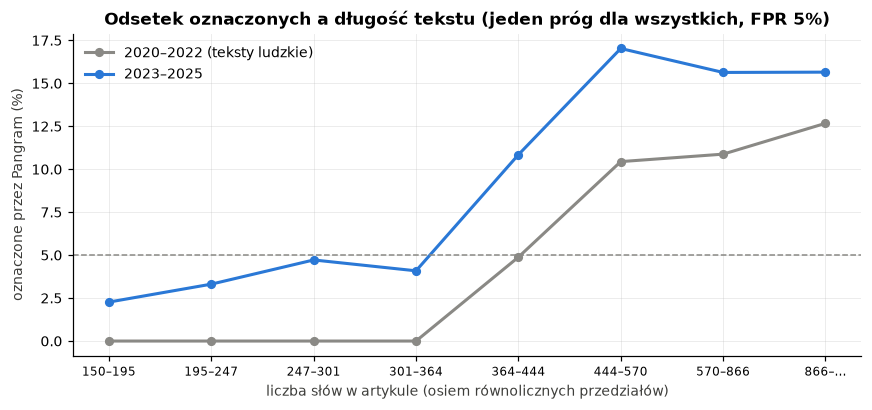

Mediana długości: 2020–22 366 słów, 2023–25 360 słów.


In [21]:
edges = np.quantile(data["n_words"], np.linspace(0, 1, 9))
edges[0], edges[-1] = -np.inf, np.inf
data["len_bin"] = pd.cut(data["n_words"], edges, labels=False)
labels = [f"{int(a) if np.isfinite(a) else 150}–{int(b) if np.isfinite(b) else '…'}" for a, b in zip(edges[:-1], edges[1:])]

fig, ax = plt.subplots(figsize=(8, 3.8))
for human, label, color in ((True, "2020–2022 (teksty ludzkie)", GRAY), (False, "2023–2025", BLUE)):
    mask = data["human"] == human
    rate = flags_main[mask].groupby(data.loc[mask, "len_bin"]).mean()
    ax.plot(rate.index, 100 * rate, color=color, lw=2, marker="o", ms=5, label=label)
ax.axhline(100 * MAIN_FPR, color=GRAY, ls="--", lw=1)
ax.set_xticks(range(8), labels, fontsize=8)
ax.set_xlabel("liczba słów w artykule (osiem równolicznych przedziałów)")
ax.set_ylabel("oznaczone przez Pangram (%)")
ax.set_title(f"Odsetek oznaczonych a długość tekstu (jeden próg dla wszystkich, FPR {pct(MAIN_FPR, 0)})")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
mean_len = data.groupby("human")["n_words"].median()
print(f"Mediana długości: 2020–22 {mean_len[True]:.0f} słów, 2023–25 {mean_len[False]:.0f} słów.")

In [22]:
gold_len = data.drop_duplicates("article_id").set_index("article_id")["len_bin"]
gold_bins = gold_len.reindex(gold_ai.index)
assert gold_bins.notna().all()


def length_flags(fpr: float) -> tuple[pd.Series, int, int]:
    flags = pd.Series(False, index=data.index)
    gold_flags = pd.Series(False, index=gold_ai.index)
    for b in range(8):
        in_bin = data["len_bin"] == b
        t = threshold_at_fpr(data.loc[CALIBRATION & in_bin, SCORE], fpr)
        flags[in_bin] = data.loc[in_bin, SCORE] > t
        gold_flags[gold_bins == b] = gold_ai[gold_bins == b] > t
    return flags, int(gold_flags.sum()), len(gold_flags)


flags_len, k_len, n_len = length_flags(MAIN_FPR)
delta_len = float(np.quantile(placebo_changes(flags_len), PLACEBO_Q))
domains_len = domain_shares(flags_len, k_len, n_len, delta_len)
print(f"Próg w przedziałach długości: TPR na G2 = {pct(k_len / n_len, 0)}, δ = {100 * delta_len:.1f} pp")
display(pd.DataFrame({
    "jeden próg": overall(flags_main, k_tpr, n_tpr),
    "próg w przedziałach długości": overall(flags_len, k_len, n_len),
}).T)

masowe_len = sorted(set(masowe) | set(domains_len.index[domains_len["grupa"].isin(CATEGORIES[:2])]))
compare = pd.DataFrame({
    "jeden próg: π_gold / π_min": [f"{pct(domains.loc[d, 'π_gold'], 0)} / {pct(domains.loc[d, 'π_min'], 0)}" for d in masowe_len],
    "jeden próg: grupa": domains.loc[masowe_len, "grupa"],
    "próg wg długości: π_gold / π_min": [f"{pct(domains_len.loc[d, 'π_gold'], 0)} / {pct(domains_len.loc[d, 'π_min'], 0)}" for d in masowe_len],
    "próg wg długości: grupa": domains_len.loc[masowe_len, "grupa"],
}, index=masowe_len)
display(compare)
display(pd.DataFrame({
    "jeden próg": domains["grupa"].value_counts(),
    "próg wg długości": domains_len["grupa"].value_counts(),
}).reindex(CATEGORIES, fill_value=0))

Próg w przedziałach długości: TPR na G2 = 49%, δ = 3.4 pp


,tekstów 2023–25,oznaczone: poziom bazowy (skład 2023–25),oznaczone: 2023–25,nadwyżka (pp),"π_min: udział AI, dolna granica [95% CI]",π_gold: udział AI przy TPR z G2 [95% CI]
jeden próg,14167,4.7%,8.6%,+3.8,4.0% [2.4%; 6.1%],18.1% [9.7%; 32.2%]
próg w przedziałach długości,14167,4.7%,12.1%,+7.4,7.8% [5.3%; 10.4%],16.7% [11.0%; 24.4%]


,jeden próg: π_gold / π_min,jeden próg: grupa,próg wg długości: π_gold / π_min,próg wg długości: grupa
elblag.net,43% / 9%,nadwyżka poniżej progu,42% / 19%,masowo: prawdopodobnie
globalna.info,46% / 8%,nadwyżka poniżej progu,13% / 6%,nadwyżka poniżej progu
goniec.pl,50% / 11%,masowo: prawdopodobnie,33% / 16%,masowo: prawdopodobnie
lelum.pl,30% / 7%,nadwyżka poniżej progu,4% / 2%,brak nadwyżki ponad dryf
nczas.com,40% / 9%,masowo: prawdopodobnie,21% / 10%,nadwyżka poniżej progu
o2.pl,16% / 4%,nadwyżka poniżej progu,35% / 16%,masowo: prawdopodobnie
tvmalbork.pl,30% / 7%,nadwyżka poniżej progu,38% / 18%,masowo: prawdopodobnie
zmianynaziemi.pl,100% / 35%,masowo: mocne dowody,100% / 47%,masowo: mocne dowody


,jeden próg,próg wg długości
grupa,,
masowo: mocne dowody,1,1
masowo: prawdopodobnie,2,4
nadwyżka poniżej progu,14,20
brak nadwyżki ponad dryf,20,12


**Jak to czytać:**

- **Wykres:** w latach 2020–2022 **żaden** tekst krótszy niż około 360 słów nie przekracza progu, a wszystkie fałszywe alarmy pochodzą z dłuższych tekstów. W latach 2023–2025 oznaczane są już także krótkie teksty (2–5%). Wzrost jest więc widoczny w każdej długości tekstu, a nie tylko w długich.
- **Długość artykułów się nie zmieniła** (mediana 366 słów przed i 360 po), więc zmiana długości nie może wyjaśnić wzrostu ogólnego.
- **Wynik ogólny po poprawce na długość jest zgodny z głównym:** π_gold 17% (wobec 18%), π_min 8% (wobec 4%). Dolna granica rośnie, bo próg w przedziałach długości lepiej wychwytuje oznaczenia krótkich tekstów.
- **Na poziomie serwisów** `zmianynaziemi.pl` i `goniec.pl` zostają w swoich grupach. `nczas.com` i `lelum.pl` spadają, a `elblag.net`, `o2.pl` i `tvmalbork.pl` awansują do „prawdopodobnie”. Te zmiany pokazują, które wyniki są kruche, i potwierdzają, że stabilne są tylko `zmianynaziemi.pl` i `goniec.pl`.

### 7.3. Inna definicja „masowo”

Próg 20% jest umowny. Liczba serwisów w grupach „masowo” przy progu 10%, 20% i 30%:

In [29]:
sens = {}
for mass in (0.10, 0.20, 0.30):
    table = domain_shares(flags_main, k_tpr, n_tpr, DELTA, mass=mass)
    sens[f"„masowo” ≥ {pct(mass, 0)}"] = table["grupa"].value_counts().reindex(CATEGORIES, fill_value=0)
display(pd.DataFrame(sens).T)

grupa,masowo: mocne dowody,masowo: prawdopodobnie,nadwyżka poniżej progu,brak nadwyżki ponad dryf
„masowo” ≥ 10%,1,9,7,20
„masowo” ≥ 20%,1,2,14,20
„masowo” ≥ 30%,0,1,16,20


**Jak to czytać:** przy łagodniejszej definicji (≥ 10%) „prawdopodobnie masowych” jest 9 serwisów, przy ostrzejszej (≥ 30%) tylko 1 (`zmianynaziemi.pl`). **Liczba serwisów silnie zależy od definicji „masowo”**, dlatego w raporcie podajemy ją razem z definicją i pokazujemy tę tabelę.

### 7.4. Inny margines dryfu (90. i 99. percentyl placebo)

Margines δ to granica, powyżej której zmianę w serwisie uznajemy za coś więcej niż szum. Jego wybór to kompromis:

- **niższy percentyl (90%)** daje mniejsze δ: łapiemy mniejsze nadwyżki, ale średnio co dziesiąty serwis **bez AI** przekroczyłby δ przypadkiem (więcej fałszywych wskazań);
- **wyższy percentyl (99%)** daje większe δ: fałszywych wskazań prawie nie ma, ale gubimy mniejsze, prawdziwe nadwyżki. Do tego 99. percentyl ze 110 porównań placebo to w praktyce jedna-dwie najbardziej skrajne wartości, więc samo δ jest słabo oszacowane.

In [24]:
rows = {}
for q in (0.90, 0.95, 0.99):
    d = float(np.quantile(placebo, q))
    table = domain_shares(flags_main, k_tpr, n_tpr, d)
    rows[f"PLACEBO_Q = {pct(q, 0)}"] = {
        "δ (pp)": f"{100 * d:.1f}",
        **table["grupa"].value_counts().reindex(CATEGORIES, fill_value=0).to_dict(),
        "„masowe” (obie grupy)": ", ".join(table.index[table["grupa"].isin(CATEGORIES[:2])]),
    }
display(pd.DataFrame(rows).T)

,δ (pp),masowo: mocne dowody,masowo: prawdopodobnie,nadwyżka poniżej progu,brak nadwyżki ponad dryf,„masowe” (obie grupy)
PLACEBO_Q = 90%,2.3,1,2,16,18,"zmianynaziemi.pl, goniec.pl, nczas.com"
PLACEBO_Q = 95%,2.9,1,2,14,20,"zmianynaziemi.pl, goniec.pl, nczas.com"
PLACEBO_Q = 99%,4.7,1,2,10,24,"zmianynaziemi.pl, goniec.pl, nczas.com"


**Jak to czytać:**

- **Lista serwisów „masowych” nie zależy od δ.** Przy każdym percentylu to te same trzy serwisy. Warunek „masowo” wymaga, żeby dolna granica przedziału ufności udziału AI przekroczyła 20%. Nadwyżki tych serwisów (od około 9 pp do 33 pp) są dużo większe niż którekolwiek δ (2,3–4,7 pp), więc margines dryfu nie ma tu znaczenia.
- **δ zmienia tylko granicę między „nadwyżką poniżej progu” a „brakiem nadwyżki”:** 16, 14 albo 10 serwisów. Od δ zależy więc odpowiedź na pytanie „w ilu serwisach jest jakikolwiek sygnał AI”, ale nie odpowiedź na pytanie badawcze.
- **Czego się spodziewać:** przy 90. percentylu około 10% serwisów bez AI przekracza δ przypadkiem, czyli przy około 20 serwisach bez sygnału to około dwóch fałszywych wskazań. Przy 99. percentylu jest ich praktycznie zero, ale tracimy cztery serwisy z nadwyżką 3–5 pp, których nie umiemy odróżnić od dryfu.
- **Wybieramy 95%**, bo to konwencja (odpowiada poziomowi istotności 5%) i kompromis między tymi dwoma błędami.

## 8. Porównanie z detektorami opartymi na Bieliku

Przed zbudowaniem zbioru gold głównymi kandydatami były Binoculars i Fast-DetectGPT na polskim modelu Bielik. Porównanie ich z Pangramem to osobny wynik badania: **detektor, który dobrze działa na jednym zbiorze odniesienia (Śmigiel), może nie działać na innym (gold)**, a dobór instrumentu zmienia odpowiedź na pytanie badawcze.

**Decyzje:**

- **Para Bielik 4.5B.** Na Śmigielu działa nieco lepiej niż 1.5B. Zbiór gold policzono tylko dla 1.5B, ale na Śmigielu oba modele dają prawie te same krzywe ROC (sekcja 2), więc zakładamy, że wniosek z gold dotyczy też 4.5B.
- **Fast-DetectGPT w wariancie z modelem bazowym** (*observer*): to standardowa wersja metody i na Śmigielu ma wyższe AUC niż wariant z modelem instrukcyjnym.
- **Ta sama procedura co dla Pangrama:** próg przy FPR 5% na tekstach z lat 2020–2022 (train + dev), poziom bazowy każdego serwisu, margines dryfu z placebo.
- **Bez π_gold.** Czułości Bielika 4.5B na tekstach typu GPT nie znamy (dla 1.5B jest bliska FPR). Liczymy tylko π_min, czyli dolną granicę, która obowiązuje dla każdego detektora.

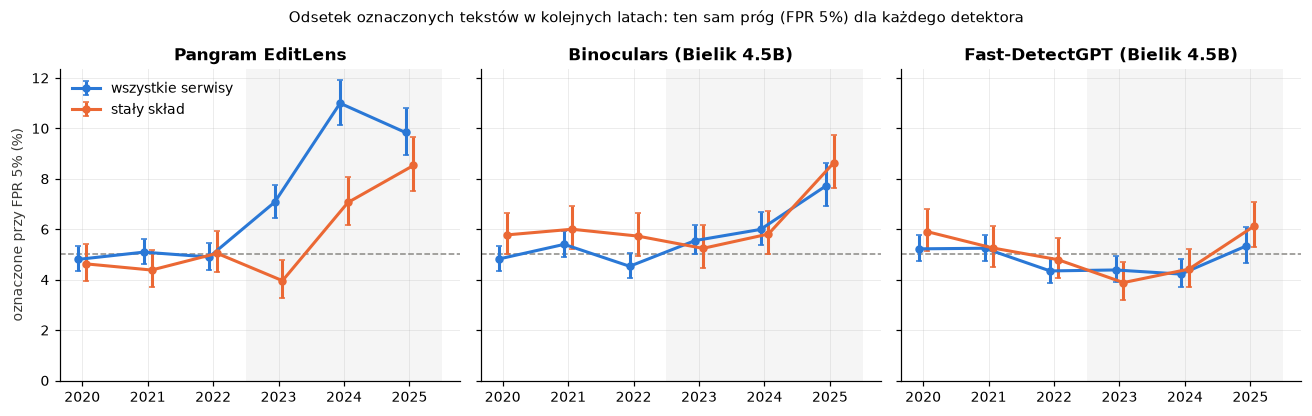

In [25]:
bielik45 = data[["text_key"]].merge(pd.read_csv(DETECT / "bielik-4.5b.csv"), on="text_key", how="left")
bielik45.index = data.index
assert bielik45["binoculars"].notna().all(), "brakuje wyników Bielika 4.5B dla części artykułów"

COMPARE = {SCORE: "Pangram EditLens", "binoculars": "Binoculars (Bielik 4.5B)",
           "fastdetectgpt_observer": "Fast-DetectGPT (Bielik 4.5B)"}
machine_cmp = {column: (data[SCORE] if column == SCORE else DIRECTIONS[column] * bielik45[column]) for column in COMPARE}
flags_cmp = {column: m > threshold_at_fpr(m[CALIBRATION], MAIN_FPR) for column, m in machine_cmp.items()}
delta_cmp = {column: float(np.quantile(placebo_changes(f), PLACEBO_Q)) for column, f in flags_cmp.items()}
# Korelacje rang (Spearmana) liczymy jako korelację Pearsona na rangach.
# TPR nieznany: domain_shares liczymy tylko dla π_min (kolumny π_gold i „grupa” pomijamy)
shares_cmp = {column: domain_shares(f, 1, 1, delta_cmp[column]) for column, f in flags_cmp.items()}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (column, title) in zip(axes, COMPARE.items()):
    ax.axvspan(2022.5, 2025.5, color=GRAY, alpha=0.08, lw=0)
    ax.axhline(100 * MAIN_FPR, color=GRAY, ls="--", lw=1)
    for mask, label, color, shift in (
        (data["domain"].notna(), "wszystkie serwisy", BLUE, -0.06),
        (data["domain"].isin(balanced), "stały skład", ORANGE, 0.06),
    ):
        t = flags_cmp[column][mask].groupby(data.loc[mask, "pub_year"]).agg(["sum", "size"])
        rate = t["sum"] / t["size"]
        ci = np.array([wilson_interval(int(k), int(n)) for k, n in t.to_numpy()])
        ax.errorbar(t.index + shift, 100 * rate, yerr=[100 * (rate - ci[:, 0]), 100 * (ci[:, 1] - rate)],
                    color=color, lw=2, marker="o", ms=4.5, capsize=2, label=label)
    ax.set_title(title)
    ax.set_xticks(range(2020, 2026))
    ax.set_ylim(0, None)
axes[0].set_ylabel(f"oznaczone przy FPR {pct(MAIN_FPR, 0)} (%)")
axes[0].legend(loc="upper left")
fig.suptitle("Odsetek oznaczonych tekstów w kolejnych latach: ten sam próg (FPR 5%) dla każdego detektora", fontsize=10)
fig.tight_layout()
plt.show()

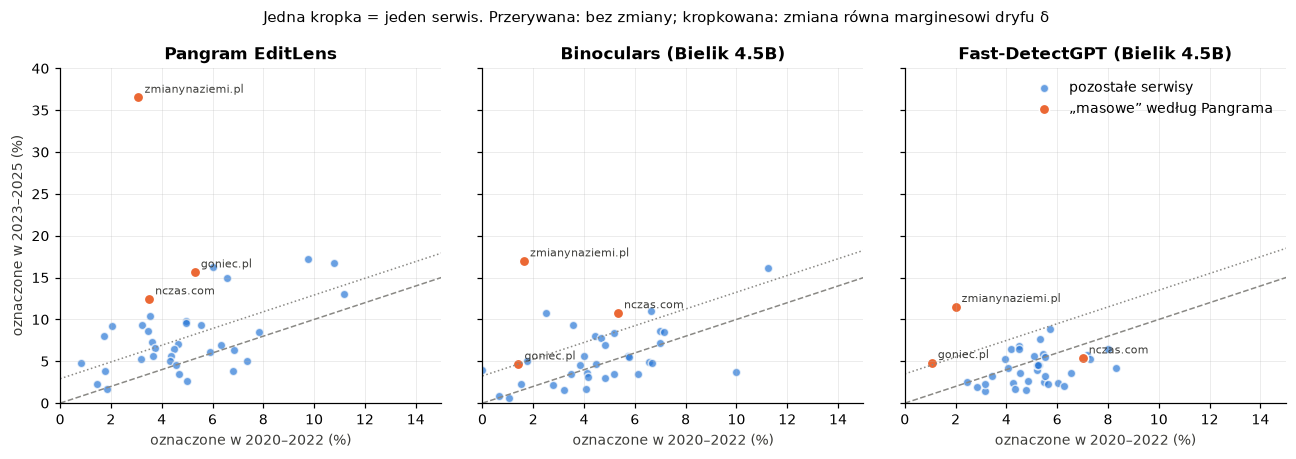

In [26]:
mass_domains = list(domains.index[domains["grupa"].isin(CATEGORIES[:2])])
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharex=True, sharey=True)
for ax, (column, title) in zip(axes, COMPARE.items()):
    t = shares_cmp[column]
    other = ~t.index.isin(mass_domains)
    ax.plot([0, 40], [0, 40], color=GRAY, ls="--", lw=1)
    ax.plot([0, 40], [100 * delta_cmp[column], 40 + 100 * delta_cmp[column]], color=GRAY, ls=":", lw=1)
    ax.scatter(100 * t.loc[other, "b"], 100 * t.loc[other, "r"], s=30, color=BLUE, alpha=0.7,
               edgecolor="white", linewidth=1, label="pozostałe serwisy")
    ax.scatter(100 * t.loc[mass_domains, "b"], 100 * t.loc[mass_domains, "r"], s=46, color=ORANGE,
               edgecolor="white", linewidth=1, label="„masowe” według Pangrama")
    for domain in mass_domains:
        ax.annotate(domain, (100 * t.loc[domain, "b"], 100 * t.loc[domain, "r"]), xytext=(4, 3),
                    textcoords="offset points", fontsize=7, color=INK)
    ax.set_title(title)
    ax.set_xlabel("oznaczone w 2020–2022 (%)")
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 40)
axes[0].set_ylabel("oznaczone w 2023–2025 (%)")
axes[2].legend(loc="upper right")
fig.suptitle("Jedna kropka = jeden serwis. Przerywana: bez zmiany; kropkowana: zmiana równa marginesowi dryfu δ", fontsize=10)
fig.tight_layout()
plt.show()

In [27]:
reference_auc = {
    SCORE: (smigiel, gold[gold["detector"] == "pangram"]),
    "binoculars": (smigiel45, gold[gold["detector"] == "binoculars"]),
    "fastdetectgpt_observer": (smigiel45, gold[gold["detector"] == "fdgpt_observer"]),
}
excess_pg = shares_cmp[SCORE]["nadwyżka"]
rows = {}
for column, title in COMPARE.items():
    frame, gold_rows = reference_auc[column]
    machine = DIRECTIONS[column] * frame[column]
    pairs = gold_rows.pivot(index="pair_id", columns="label", values="score")
    total = overall(flags_cmp[column], 1, 1)
    t = shares_cmp[column]
    rows[title] = {
        "AUC Śmigiel": f"{auc(machine[frame['label'] == 1], machine[frame['label'] == 0]):.2f}",
        "AUC gold": f"{auc(pairs['ai'], pairs['human']):.2f}" + ("" if column == SCORE else " (1.5B)"),
        "oznaczone: poziom bazowy": total["oznaczone: poziom bazowy (skład 2023–25)"],
        "oznaczone: 2023–25": total["oznaczone: 2023–25"],
        "ogółem π_min [95% CI]": total["π_min: udział AI, dolna granica [95% CI]"],
        "δ (pp)": f"{100 * delta_cmp[column]:.1f}",
        "serwisy z nadwyżką > δ": int((t["nadwyżka"] > delta_cmp[column]).sum()),
        **{f"{d}: π_min [95% CI]": pct_ci(*t.loc[d, ["π_min", "π_min low", "π_min high"]]) for d in mass_domains},
        "korelacja z Pangramem: teksty": f"{machine_cmp[column].rank().corr(machine_cmp[SCORE].rank()):.2f}",
        "korelacja z Pangramem: nadwyżki serwisów": f"{t['nadwyżka'].rank().corr(excess_pg.rank()):.2f}",
    }
display(pd.DataFrame(rows))

,Pangram EditLens,Binoculars (Bielik 4.5B),Fast-DetectGPT (Bielik 4.5B)
AUC Śmigiel,0.80,0.85,0.80
AUC gold,0.88,0.56 (1.5B),0.49 (1.5B)
oznaczone: poziom bazowy,4.7%,5.0%,4.9%
oznaczone: 2023–25,8.6%,6.0%,4.5%
ogółem π_min [95% CI],4.0% [2.4%; 6.1%],1.1% [0.0%; 2.4%],0.0% [0.0%; 0.5%]
δ (pp),2.9,3.3,3.5
serwisy z nadwyżką > δ,17,9,2
zmianynaziemi.pl: π_min [95% CI],34.5% [28.9%; 40.2%],15.6% [11.4%; 20.2%],9.7% [6.1%; 13.6%]
goniec.pl: π_min [95% CI],10.9% [6.8%; 14.9%],3.3% [0.9%; 5.5%],3.8% [1.5%; 5.9%]
nczas.com: π_min [95% CI],9.3% [5.0%; 14.0%],5.8% [1.5%; 10.5%],0.0% [0.0%; 2.3%]


**Jak to czytać:**

- **Na Śmigielu detektory Bielika są tak dobre jak Pangram albo lepsze** (AUC 0,80–0,85 wobec 0,80). **Na gold nie działają** (AUC 0,49–0,56 wobec 0,88). Śmigiel zawiera krótkie teksty z modeli open-source (w tym samego Bielika), a gold to przeróbki prawdziwych newsów przez GPT, które zachowują fakty, nazwiska i cytaty z ludzkiego oryginału. Prawdopodobne wyjaśnienie: Binoculars i Fast-DetectGPT mierzą, jak bardzo tekst jest „przewidywalny” dla Bielika, a przeróbka GPT jest dla Bielika równie przewidywalna jak tekst ludzki.
- **Na naszych danych detektory Bielika nie pokazują prawie żadnego wzrostu.** Binoculars oznacza 5,0% tekstów przed 2023 r. i 6,0% po, a Fast-DetectGPT 4,9% i 4,5%. Dolna granica udziału AI w całej próbie to 1% i 0%, wobec 4% u Pangrama. Niewielki wzrost widać dopiero w 2025 r. Biorąc pod uwagę wynik na gold, to **nie dowód braku AI, tylko skutek ślepoty instrumentu** na teksty typu GPT.
- **Mierzą coś zupełnie innego niż Pangram.** Korelacja rang wyników tych samych tekstów z Pangramem wynosi 0,02–0,08, czyli praktycznie zero. Nadwyżki serwisów korelują słabo (około 0,2).
- **Wyjątek: `zmianynaziemi.pl`** wyróżnia się we wszystkich trzech detektorach. W Binoculars odsetek oznaczonych rośnie z 1,6% do 17,0% (π_min 16% [11; 20]), w Fast-DetectGPT π_min wynosi 10% [6; 14]. Detektory zbudowane na zupełnie innej zasadzie (prawdopodobieństwo tekstu w polskim modelu zamiast klasyfikatora uczonego na angielskim) wskazują ten sam serwis. To **niezależne potwierdzenie** najmocniejszego wyniku. Skoro Bielik nie widzi przeróbek GPT, a teksty z tego serwisu widzi, są one prawdopodobnie innego rodzaju (generowane od zera albo innym modelem). Zgadza się to z π_gold powyżej 100% u Pangrama.
- `goniec.pl` i `nczas.com` mają w detektorach Bielika co najwyżej mały wzrost (π_min 0–6%), więc tu potwierdzenia nie ma. Przy ślepocie Bielika na teksty GPT nie jest to jednak dowód przeciw.

**Wniosek do raportu:** gdybyśmy wybrali detektor tylko na podstawie Śmigiela (tak jak zwycięskie zgłoszenie PolEval), wybralibyśmy Binoculars i odpowiedzielibyśmy, że wzrostu prawie nie ma. **Wybór instrumentu zmienia odpowiedź na pytanie badawcze**, a walidacja na danych podobnych do badanych (gold) jest niezbędna. Sama walidacja na zbiorze z innej dziedziny wprowadziłaby nas w błąd.

## 9. Wnioski i ograniczenia

### Odpowiedź na pytanie badawcze

> **W naszej próbie 37 polskich serwisów, które da się porównać przed i po 2022 r., jeden serwis (`zmianynaziemi.pl`) publikuje masowo treści generowane przez AI (co najmniej 29% tekstów z lat 2023–2025, niezależnie od założeń o czułości detektora). Drugi (`goniec.pl`) prawdopodobnie też (około 36–51% przy czułości zmierzonej na przeróbkach GPT, stabilnie we wszystkich wariantach analizy). Poza porównaniem mocną poszlakę daje `neon24.pl` (45% oznaczonych tekstów w 2023 r.). Żaden z największych serwisów (S1) nie spełnia kryterium.**
>
> W całej próbie udział tekstów AI w latach 2023–2025 szacujemy na **od kilku do kilkunastu procent** (dolna granica 4%, górna około 18%; przy różnych progach szacunki zbiegają się w okolicy 8–11%). Zjawisko jest wyraźne dopiero od 2024 r.
>
> „Masowo” rozumiemy jako co najmniej 20% artykułów. Przy progu 10% serwisów „masowych” (obie grupy razem) byłoby 10, przy progu 30% jeden.

### Na czym opiera się wniosek

1. **Instrument zwalidowany na danych odniesienia:** Pangram odróżnia przeróbki GPT od polskich newsów (AUC 0,88). Detektory oparte na Bieliku tego nie potrafią (AUC około 0,5), choć dobrze działają na Śmigielu, więc nie używamy ich w pomiarze. Na naszych danych prawie nie pokazują wzrostu, co jest skutkiem ślepoty na teksty typu GPT, a nie dowodem braku AI (sekcja 8).
2. **Kalibracja na tekstach ludzkich:** próg ustawiony na około 19 tys. tekstów z lat 2020–2022 i sprawdzony na odłożonych tekstach.
3. **Kontrole:** odsetek oznaczonych jest płaski w latach 2020–2022. Zmiany w serwisach bez AI rzadko przekraczają 3 pp. Wzrost jest widoczny przy stałym składzie serwisów i w każdym przedziale długości tekstu.
4. **Odporność:** dwa wskazane serwisy są „masowe” przy każdym progu, po poprawce na długość i przy każdym marginesie dryfu.
5. **Niezależne potwierdzenie:** `zmianynaziemi.pl` wyróżnia się także w obu detektorach opartych na Bieliku, które działają na zupełnie innej zasadzie (sekcja 8).

### Ograniczenia

- **Czułość znamy tylko dla jednego rodzaju tekstów AI:** przeróbek polskich newsów przez `gpt-4.1-mini` (100 par). Dla tekstów pisanych od zera, innymi modelami albo poprawianych przez człowieka może być inna. Dlatego podajemy przedział (π_min do π_gold), a nie jedną liczbę. Przedziały dla pojedynczych serwisów są szerokie.
- **Pangram był uczony na tekstach angielskich.** Na polskich newsach działa (gold, Śmigiel), ale jego wynik zależy od długości tekstu. Uwzględniamy to w analizie odporności, nie w modelu.
- **Założenie, że teksty z lat 2020–2022 są ludzkie, a detektor nie zmienia się w czasie bez AI.** Placebo pokazuje stabilność w latach 2020–2022, ale nie wyklucza zmiany, która zaczęła się dokładnie po 2022 r. z innego powodu (nowy szablon strony, nowa moda redakcyjna).
- **Korelacja, nie przyczynowość.** Wzrost pokrywa się w czasie z dostępnością LLM-ów i z tym, co detektor rozpoznaje jako AI, ale nie mamy bezpośredniego dowodu (np. ręcznej oceny ani deklaracji redakcji), że te konkretne teksty wygenerowała AI.
- **Próba jest celowa** (44 serwisy, S3 wybrane jako podejrzane), a 8 serwisów nie ma porównania przed/po. Wniosków nie uogólniamy na wszystkie polskie serwisy.
- **Wiele serwisów naraz:** przy 37 przedziałach ufności można się spodziewać, że w około jednym serwisie dolna granica przekroczy próg przypadkiem. Dlatego za wynik uznajemy tylko serwisy stabilne we wszystkich wariantach analizy.